# Micro-TDE cross sections from binary$-$single scattering

**Rebuilt on the full production run** ($2.76\times10^{7}$ simulations, impact parameter sampled
$b^2\sim\mathcal U[0,b_{\max}^2]$).  A *micro-TDE* ($\mu$TDE) is the tidal disruption of the star by
its stellar-mass companion black hole **BH1** ($10\,M_\odot$) while the BH1$-$star binary
($m_{\rm bin}=11\,M_\odot$) encounters a central massive black hole **BH$_\bullet$** of mass $M_\bullet$.
Outcome label in the raw data: `TDE:star2_by_bh1`.

This notebook computes **only** the $\mu$TDE cross section $\sigma_\mu(M_\bullet,a,e,v_\infty)$ and the
quantities built from it: heatmaps, a semi-analytic closed form, eccentricity-averaged fractions,
and the population-averaged $\langle\sigma(M_\bullet,v)\rangle$ for three Stone & Leigh $p(a,e)$
assumptions.  No EMRI / HVS / merger-timescale / rate-normalisation content.

**Contents**
1. Setup, style, shared helpers
2. Data provenance & domains of validity
3. Load the cell summary; build $\sigma_\mu(M_\bullet,a,e,v)$ with binomial errors
4. Cross-section heatmaps (hard vs soft binary; $e=0$ vs $e=0.9$)
5. Relative statistical error (separate figure)
6. How $\sigma_\mu$ varies across the grid
7. **Semi-analytic $f_\mu$**: the penetration-threshold closed form $\beta_{\rm crit}(\rho,e)$
8. Three $p(a,e)$ regimes and the eccentricity-averaged $f_\mu$
9. **Population average $\langle\sigma(M_\bullet,v)\rangle\pm$ error** for the three $p(a,e)$
10. Cross section along the $M_\bullet$–$\sigma$ (Kormendy & Ho) relation
11. **Rate per number density $\langle\sigma_\mu v\rangle(M_\bullet)$** for the three $p(a,e)$
12. Emulator: grid interpolation of $\sigma_\mu$
13. Convergence & caveats

## 1. Setup, style, and shared helpers

All plotting conventions live here so every figure is consistent: Computer-Modern (LaTeX) fonts via
mathtext `cm`, ticks pointing **in** on all four sides with minor ticks, no grid, one fixed box
aspect ratio, the colour-blind-safe **Okabe$-$Ito** palette for lines and **cividis** for heatmaps.

In [1]:
import numpy as np, csv
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm

# numpy 1.x / 2.x compatibility for the trapezoidal rule
trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 150,
    "font.size": 13, "axes.titlesize": 14.5, "axes.labelsize": 15.5,
    "legend.fontsize": 11.5, "xtick.labelsize": 13, "ytick.labelsize": 13,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
    "xtick.minor.visible": True, "ytick.minor.visible": True,
    "xtick.major.size": 7.0, "ytick.major.size": 7.0,
    "xtick.minor.size": 4.0, "ytick.minor.size": 4.0,
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.minor.width": 0.7, "ytick.minor.width": 0.7,
    "axes.grid": False, "axes.linewidth": 0.9,
    "figure.facecolor": "white", "savefig.facecolor": "white",
    "font.family": "serif", "font.serif": ["cmr10", "DejaVu Serif"],
    "mathtext.fontset": "cm", "axes.formatter.use_mathtext": True, "axes.unicode_minus": False,
})

PANEL_ASPECT = 0.82
def style_axes(ax, logx=False, logy=False):
    ax.set_box_aspect(PANEL_ASPECT)
    if logx: ax.set_xscale("log")
    if logy: ax.set_yscale("log")
    return ax

OI = dict(black="#000000", orange="#E69F00", skyblue="#56B4E9", green="#009E73",
          blue="#0072B2", vermillion="#D55E00", purple="#CC79A7", grey="#8C8C8C")

CIVIDIS = mpl.colormaps["cividis"].copy()
CIVIDIS.set_bad("#e9e9e9")   # cells with NO mu-TDE detected -> light grey

def whiten_ticks(ax):
    ax.tick_params(which="both", color="white")
    for sp in ax.spines.values(): sp.set_edgecolor("0.2")
def whiten_cbar(cb):
    cb.ax.tick_params(which="both", color="white"); cb.outline.set_edgecolor("0.2")

def _label_even_pow(val, pos):
    """Label only exact powers of ten with EVEN exponent -> one label every 2 dex."""
    if val <= 0: return ""
    e = np.log10(val)
    if abs(e - round(e)) > 1e-3: return ""
    e = int(round(e)); return rf"$10^{{{e}}}$" if e % 2 == 0 else ""
def log_axis_dex(axis):
    axis.set_major_locator(mticker.LogLocator(base=10, numticks=500))
    axis.set_major_formatter(mticker.FuncFormatter(_label_even_pow))
    axis.set_minor_locator(mticker.LogLocator(base=10, subs=np.arange(2,10), numticks=500))
    axis.set_minor_formatter(mticker.NullFormatter())

def edges(centers, log=True):
    c = np.log10(np.asarray(centers,float)) if log else np.asarray(centers,float)
    e = np.empty(c.size+1); e[1:-1] = 0.5*(c[:-1]+c[1:])
    e[0] = c[0]-(c[1]-c[0])/2; e[-1] = c[-1]+(c[-1]-c[-2])/2
    return 10**e if log else e

print("style & helpers ready - box aspect", PANEL_ASPECT)

style & helpers ready - box aspect 0.82


## 2. Data provenance & domains of validity

**What was simulated.** A three-body scattering sweep (SpaceHub, PN-capable) of a BH1$-$star inner
binary on a near-parabolic orbit about BH$_\bullet$.  The grid is

| parameter | nodes |
|---|---|
| $M_\bullet$ | 19 half-decade values, $10^{1}$ to $10^{10}\,M_\odot$ |
| $a_{\rm bin}$ | 13 values, $0.03$ to $30$ AU |
| $e_{\rm bin}$ | 12 values, $0$ to $0.99$ (denser near 1) |
| $v_\infty/v_{\rm orb}$ | 7 values, $10^{-3}$ to $10$ |

For every surviving $(M_\bullet,a,e,v)$ cell, $N\simeq1500$ encounters were drawn with **impact
parameter $b^2\sim\mathcal U[0,b_{\max}^2]$** (equal area per annulus, the physically correct
measure), isotropic orientation ($\cos\iota\sim\mathcal U[-1,1]$; $\Omega,\omega\sim\mathcal U[0,2\pi]$),
and inner phase uniform in mean anomaly.  Each encounter's penetration
$\beta=r_{t,\rm bin}/r_p$ follows from its sampled $b^2$ through the gravitational-focusing relation
$b^2=r_p^2+r_{\rm foc}r_p$, with the pericenter floored at $2r_g$.  The realised $\beta$ therefore
spans $0.037$ to $\sim5\times10^5$ (deep relativistic plungers included); $\simeq0.5\%$ of encounters
have $\beta>30$.

**Why this matters (a correction).** An earlier extract of this dataset had been *subsampled flat in
$\log\beta$ on $[0.2,30]$*, which silently reweighted the encounters and inflated the $\mu$TDE
fraction by $\sim3\times$ (it gave $f_\mu\simeq0.12$ versus the correct $0.040$).  Because the real
sweep is genuinely $b^2$-uniform, **flat counting per cell is the correct Monte-Carlo estimator** and
no reweighting is applied here.  The per-cell summary below was reduced from the full
$2.76\times10^{7}$-row run.

**$\mu$TDE condition.** A $\mu$TDE occurs when the encounter pumps the inner orbit until the star's
pericenter about BH1 falls below the stellar tidal radius
$r_{\rm TDE}=R_\star(m_1/m_\star)^{1/3}=R_\odot\cdot10^{1/3}=0.01002$ AU.

**Domains of validity.**
- Hard / intermediate binaries ($v_\infty/v_{\rm orb}\lesssim$ few) dominate the $\mu$TDE budget; the
  soft/fast corner contributes negligibly and is where any $v_\infty$ dependence would appear.
- $M_\bullet\gtrsim10^{10}\,M_\odot$: the interaction region is set by $8r_g$ rather than $10r_{t,\rm bin}$,
  direct plunges dominate, and $f_\mu\to0$ (edge of validity).
- Born-disrupted binaries ($a(1-e)<r_{\rm TDE}$, i.e. $\rho\to1$) are removed by the survival cut.

## 3. Load the cell summary and build $\sigma_\mu(M_\bullet,a,e,v)$

Per cell the Monte-Carlo cross section and its binomial error are
$$\sigma_\mu=\hat f\,\pi b_{\max}^2,\qquad
  \delta\sigma_\mu=\pi b_{\max}^2\sqrt{\frac{\hat f(1-\hat f)}{N}},\qquad \hat f=\frac{N_\mu}{N},$$
with $b_{\max}^2=r_{p,\max}^2+r_{\rm foc}r_{p,\max}$ reconstructed from each cell's geometry (it matches
the stored sweep metadata to $10^{-6}$ where present, and is defined for every cell).  We report $\sigma$ in **pc$^2$**
($1\,{\rm pc}^2=4.2545\times10^{10}\,{\rm AU}^2$) so the numbers are $\mathcal O(1)$ for rate work.

In [2]:
# ----- constants (G=1, length AU, velocity V1 km/s) -----
V1      = 29.7847                 # km/s = sqrt(G Msun / AU)
C_KMS   = 299792.458
m_bin   = 11.0                    # m1 + m2 = 10 + 1
RSUN_AU = 695700.0 / 1.495978707e8
r_TDE   = 1.0 * RSUN_AU * (10.0/1.0)**(1.0/3.0)   # R_star (m1/m_star)^1/3 = 0.01002 AU
AU2_TO_PC2 = 1.0 / 4.2545e10
FRAC_NODES = np.array([1e-3, 1e-2, 1e-1, 3e-1, 1.0, 3.0, 10.0])   # v_inf/v_orb grid

# ----- reduce the BUNDLE straight into per-(M,a,e,v) cells (no mutde_cellsummary.csv) -----
# Chunked read so the full ~2.76e7-row bundle fits in modest RAM. Set SMBH_BUNDLE to override.
import h5py, os
from collections import defaultdict
BUNDLE = os.environ.get("SMBH_BUNDLE", "../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
MU     = "TDE:star2_by_bh1"
CHUNK  = 2_000_000
n_tot, n_mu, beta_mu = defaultdict(int), defaultdict(int), defaultdict(list)
with h5py.File(BUNDLE, "r") as f:
    R = f["results"]; n = R["M_smbh"].shape[0]
    for s in range(0, n, CHUNK):
        t = min(s + CHUNK, n)
        Mc, ac = R["M_smbh"][s:t], R["a_bin"][s:t]
        ec, vc = R["e_bin"][s:t],  R["v_inf"][s:t]
        bc, oc = R["beta"][s:t],   R["outcome"].asstr()[s:t]
        frc = FRAC_NODES[np.argmin(np.abs(np.log10(vc/(V1*np.sqrt(m_bin/ac)))[:, None]
                                          - np.log10(FRAC_NODES)[None, :]), axis=1)]
        keys = list(zip(np.round(np.log10(Mc), 4), np.round(ac, 5),
                        np.round(ec, 4), np.round(np.log10(frc), 4)))
        ismu = (oc == MU)
        for k in keys: n_tot[k] += 1
        for k, b, mu in zip(keys, bc, ismu):
            if mu: n_mu[k] += 1; beta_mu[k].append(b)
_keys    = sorted(n_tot)
M        = np.array([10.0**k[0] for k in _keys])
a        = np.array([k[1]       for k in _keys])
e        = np.array([k[2]       for k in _keys])
frac     = np.array([10.0**k[3] for k in _keys])
Nt       = np.array([n_tot[k]      for k in _keys], float)
Nmu      = np.array([n_mu.get(k, 0) for k in _keys], float)
beta_med = np.array([np.median(beta_mu[k]) if beta_mu.get(k) else np.nan for k in _keys])
# snap frac to the 7 canonical nodes (keeps downstream semantics identical to the old CSV path)
frac = FRAC_NODES[np.argmin(np.abs(np.log10(frac)[:, None] - np.log10(FRAC_NODES)[None, :]), axis=1)]

# ----- b_max per cell: reconstruct analytically from the sweep's geometry (v2: rp_max=10 r_t) -----
def _bmax_AU(M, a, frac):
    m_tot = M + m_bin
    r_t   = a*(M/m_bin)**(1.0/3.0)
    v_inf = frac*V1*np.sqrt(m_bin/a)
    r_foc = 2.0*V1*V1*m_tot/v_inf**2
    r_g   = (V1*V1/(C_KMS*C_KMS))*m_tot
    rp_max= np.maximum(10.0*r_t, 8.0*r_g)
    return np.sqrt(rp_max**2 + r_foc*rp_max)
b_max_AU = _bmax_AU(M, a, frac)

# ----- per-cell sigma + binomial error (pc^2) -----
fhat     = Nmu / Nt
sig_pc2  = fhat * np.pi * b_max_AU**2 * AU2_TO_PC2
dsig_pc2 = np.pi * b_max_AU**2 * np.sqrt(np.clip(fhat*(1-fhat), 0, None)/Nt) * AU2_TO_PC2

Mgrid, agrid, egrid, fgrid = (np.unique(M), np.unique(a), np.unique(e), np.unique(frac))
print(f"cells={len(M)}  sims={int(Nt.sum()):,}  muTDEs={int(Nmu.sum()):,}  overall f_mu={Nmu.sum()/Nt.sum():.4f}")
print(f"grid: {len(Mgrid)} M x {len(agrid)} a x {len(egrid)} e x {len(fgrid)} v")
print(f"sigma range (nonzero): {sig_pc2[sig_pc2>0].min():.2e} .. {np.nanmax(sig_pc2):.2e} pc^2")
print(f"NaN sigma cells: {np.sum(~np.isfinite(sig_pc2))} (should be 0)")

# ----- fast cell lookup into a dense 4-D grid -----
iM = {round(np.log10(v),4):i for i,v in enumerate(Mgrid)}
ia = {round(v,5):i for i,v in enumerate(agrid)}
ie = {round(v,4):i for i,v in enumerate(egrid)}
ifr= {round(np.log10(v),4):i for i,v in enumerate(fgrid)}
SIG = np.full((len(Mgrid),len(agrid),len(egrid),len(fgrid)), np.nan)
DSG = np.full_like(SIG, np.nan); FMU = np.full_like(SIG, np.nan)
for k in range(len(M)):
    i,j,l,m = (iM[round(np.log10(M[k]),4)], ia[round(a[k],5)],
               ie[round(e[k],4)], ifr[round(np.log10(frac[k]),4)])
    SIG[i,j,l,m]=sig_pc2[k]; DSG[i,j,l,m]=dsig_pc2[k]; FMU[i,j,l,m]=fhat[k]
print("dense grid SIG built:", SIG.shape)

cells=18487  sims=27,633,319  muTDEs=788,113  overall f_mu=0.0285
grid: 19 M x 13 a x 12 e x 7 v
sigma range (nonzero): 4.17e-15 .. 4.33e+10 pc^2
NaN sigma cells: 0 (should be 0)
dense grid SIG built: (19, 13, 12, 7)


## 4. Cross-section heatmaps $\sigma_\mu(M_\bullet,a)$

$\sigma_\mu$ in the $(M_\bullet,a)$ plane at fixed eccentricity and velocity ratio.  Grey cells had
**no** $\mu$TDE detected in $N\simeq1500$ draws (an upper limit $\sigma<\pi b_{\max}^2/N$, not zero).
A **major tick every decade, labels every 2 decades**; colour bar in $\log_{10}\sigma[{\rm pc}^2]$.
The cross section climbs steeply toward massive $M_\bullet$ and wide $a$ because the gravitational
focusing factor $b_{\max}^2\simeq r_{\rm foc}r_{p,\max}\propto M_\bullet\,a$ grows there; higher $e$
opens disruption at shallower penetration, raising $f_\mu$ and hence $\sigma$.

/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/883399046.py:4: RuntimeWarning: divide by zero encountered in log10
  im = ax.pcolormesh(edges(Mgrid), edges(agrid), np.log10(Zm),


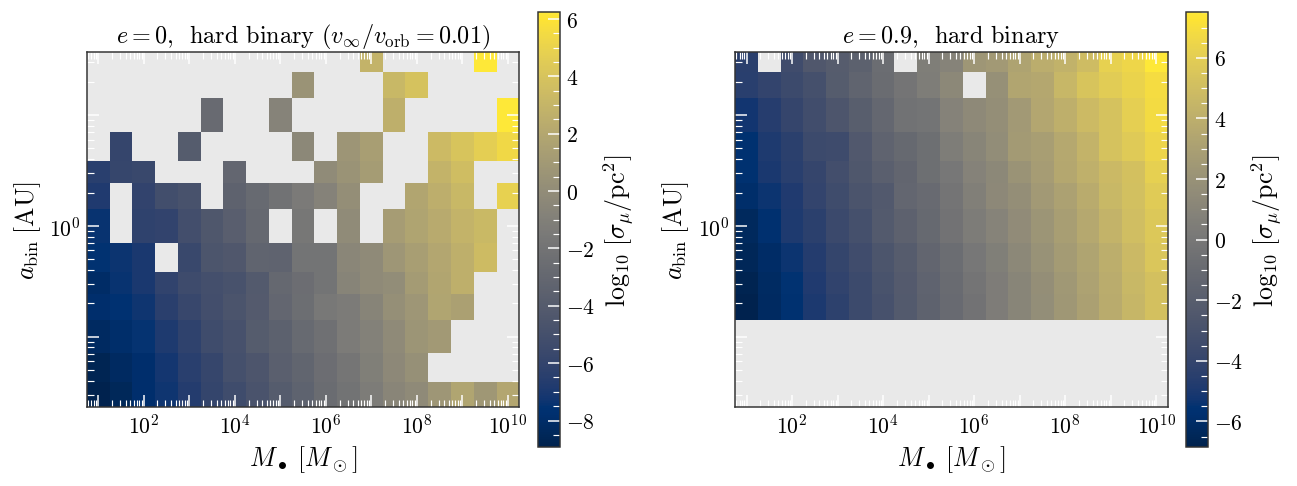

In [3]:
def heat_panel(ax, l_e, m_fr, title):
    Z = SIG[:,:,l_e,m_fr].T                         # shape (a, M)
    Zm = np.ma.masked_invalid(np.ma.masked_less_equal(Z, 0.0))
    im = ax.pcolormesh(edges(Mgrid), edges(agrid), np.log10(Zm),
                       cmap=CIVIDIS, shading="flat")
    ax.set_xscale("log"); ax.set_yscale("log")
    log_axis_dex(ax.xaxis); log_axis_dex(ax.yaxis)
    ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$")
    ax.set_title(title); ax.set_box_aspect(PANEL_ASPECT); whiten_ticks(ax)
    return im

fig, ax = plt.subplots(1, 2, figsize=(11.0, 5.0))
le0 = ie[round(egrid[np.argmin(np.abs(egrid-0.0))],4)]
le9 = ie[round(egrid[np.argmin(np.abs(egrid-0.9))],4)]
mfr = ifr[round(np.log10(0.01),4)]
im0 = heat_panel(ax[0], le0, mfr, r"$e=0$,  hard binary ($v_\infty/v_{\rm orb}=0.01$)")
im1 = heat_panel(ax[1], le9, mfr, r"$e=0.9$,  hard binary")
for im, a_ in [(im0,ax[0]), (im1,ax[1])]:
    cb = fig.colorbar(im, ax=a_, fraction=0.046, pad=0.04)
    cb.set_label(r"$\log_{10}\,[\sigma_\mu/{\rm pc}^2]$"); whiten_cbar(cb)
fig.tight_layout()
fig.savefig("mutde_heatmap.png", bbox_inches="tight")
fig.savefig("mutde_heatmap.pdf", bbox_inches="tight")
plt.show()

/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/883399046.py:4: RuntimeWarning: divide by zero encountered in log10
  im = ax.pcolormesh(edges(Mgrid), edges(agrid), np.log10(Zm),


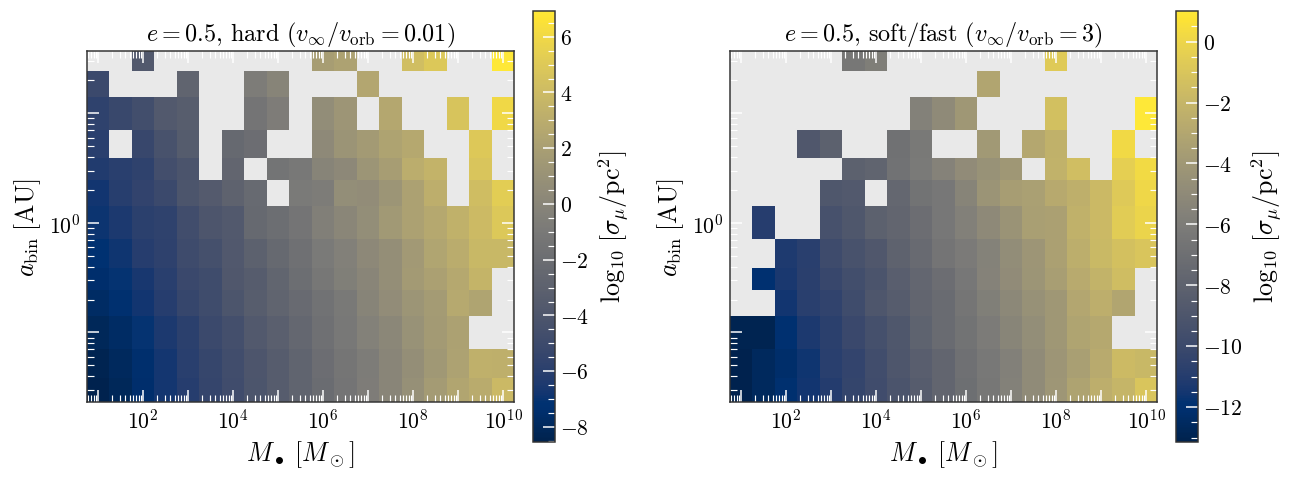

In [4]:
# soft/fast vs hard comparison at e=0.5: sigma collapses as v_inf rises (focusing weakens)
fig, ax = plt.subplots(1, 2, figsize=(11.0, 5.0))
le5 = ie[round(egrid[np.argmin(np.abs(egrid-0.5))],4)]
imh = heat_panel(ax[0], le5, ifr[round(np.log10(0.01),4)], r"$e=0.5$, hard ($v_\infty/v_{\rm orb}=0.01$)")
ims = heat_panel(ax[1], le5, ifr[round(np.log10(3.0),4)],  r"$e=0.5$, soft/fast ($v_\infty/v_{\rm orb}=3$)")
for im, a_ in [(imh,ax[0]), (ims,ax[1])]:
    cb = fig.colorbar(im, ax=a_, fraction=0.046, pad=0.04)
    cb.set_label(r"$\log_{10}\,[\sigma_\mu/{\rm pc}^2]$"); whiten_cbar(cb)
fig.tight_layout()
fig.savefig("mutde_heatmap_softhard.png", bbox_inches="tight")
fig.savefig("mutde_heatmap_softhard.pdf", bbox_inches="tight")
plt.show()

## 5. Relative statistical error (separate figure)

The fractional binomial error $\delta\sigma/\sigma=\sqrt{(1-\hat f)/(N\hat f)}$ per cell at the
baseline slice.  It is small where $\mu$TDEs are common (high $e$, wide $a$) and large in the
sparse corners; grey = no detection.

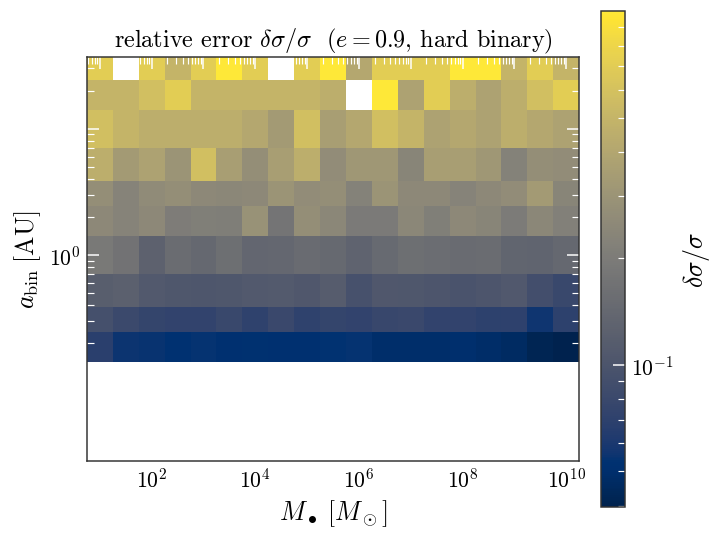

In [5]:
fig, ax = plt.subplots(figsize=(6.2, 5.2))
with np.errstate(divide="ignore", invalid="ignore"):
    rel = DSG[:,:,le9,mfr].T / SIG[:,:,le9,mfr].T
relm = np.ma.masked_invalid(rel)
im = ax.pcolormesh(edges(Mgrid), edges(agrid), relm, cmap="cividis",
                   norm=LogNorm(vmin=max(1e-2,np.nanmin(rel[rel>0])), vmax=np.nanmax(rel)),
                   shading="flat")
ax.set_xscale("log"); ax.set_yscale("log"); log_axis_dex(ax.xaxis); log_axis_dex(ax.yaxis)
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$")
ax.set_title(r"relative error $\delta\sigma/\sigma$  ($e=0.9$, hard binary)")
ax.set_box_aspect(PANEL_ASPECT); whiten_ticks(ax)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04); cb.set_label(r"$\delta\sigma/\sigma$"); whiten_cbar(cb)
fig.tight_layout()
fig.savefig("mutde_heatmap_relerr.png", bbox_inches="tight")
fig.savefig("mutde_heatmap_relerr.pdf", bbox_inches="tight")
plt.show()

## 6. How $\sigma_\mu$ varies across the grid

Line cuts with $1\sigma$ binomial bands: $\sigma_\mu$ vs $M_\bullet$ at several $a$ (left), and vs
$e$ at several $M_\bullet$ (right), all at the hard-binary slice.  $\sigma_\mu$ rises monotonically
with $M_\bullet$ (focusing) and with $e$ (easier disruption).

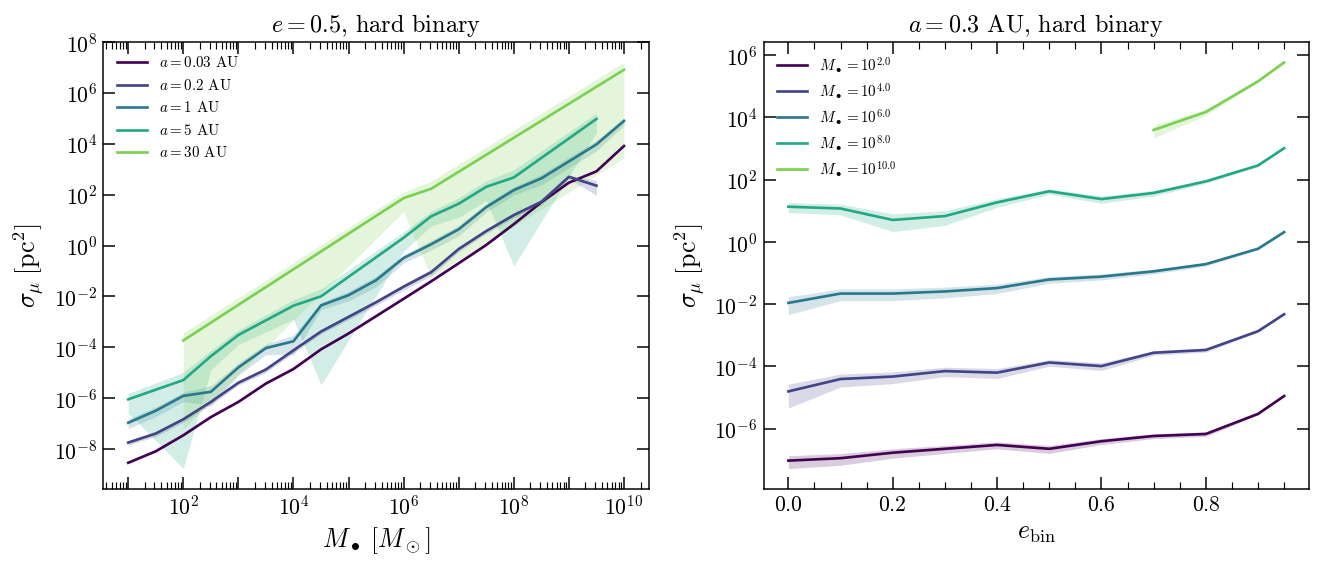

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11.2, 5.0))
cmap = mpl.colormaps["viridis"]
# left: sigma vs M at fixed e=0.5, hard, several a
for t,aa in enumerate(agrid[::3]):
    j = ia[round(aa,5)]; s = SIG[:,j,le5,mfr]; d = DSG[:,j,le5,mfr]
    good = s>0
    c = cmap(t/len(agrid[::3]))
    ax[0].plot(Mgrid[good], s[good], "-", color=c, lw=1.6, label=fr"$a={aa:g}$ AU")
    ax[0].fill_between(Mgrid[good], (s-d)[good], (s+d)[good], color=c, alpha=0.2, lw=0)
style_axes(ax[0], logx=True, logy=True); log_axis_dex(ax[0].xaxis)
ax[0].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[0].set_ylabel(r"$\sigma_\mu\;[{\rm pc}^2]$")
ax[0].set_title(r"$e=0.5$, hard binary"); ax[0].legend(frameon=False, ncol=1, fontsize=9)
# right: sigma vs e at fixed a=0.3, hard, several M
ja = ia[round(0.3,5)]
for t,mm in enumerate(Mgrid[2::4]):
    i = iM[round(np.log10(mm),4)]; s = SIG[i,ja,:,mfr]; d = DSG[i,ja,:,mfr]
    good = s>0; c = cmap(t/len(Mgrid[2::4]))
    ax[1].plot(egrid[good], s[good], "-", color=c, lw=1.6, label=fr"$M_\bullet=10^{{{np.log10(mm):.1f}}}$")
    ax[1].fill_between(egrid[good], (s-d)[good], (s+d)[good], color=c, alpha=0.2, lw=0)
style_axes(ax[1], logy=True)
ax[1].set_xlabel(r"$e_{\rm bin}$"); ax[1].set_ylabel(r"$\sigma_\mu\;[{\rm pc}^2]$")
ax[1].set_title(r"$a=0.3$ AU, hard binary"); ax[1].legend(frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig("mutde_cuts.png", bbox_inches="tight"); fig.savefig("mutde_cuts.pdf", bbox_inches="tight")
plt.show()

## 7. Semi-analytic $f_\mu$: the penetration-threshold closed form

A $\mu$TDE happens when an encounter is **deep enough** to pump the inner binary to disruption,
i.e. when the outer penetration exceeds a threshold, $\beta>\beta_{\rm crit}$.  Because $b^2$ is
sampled uniformly, the fraction of encounters with $\beta>\beta_{\rm crit}$ is a pure geometric
ratio, giving a **closed form**:
$$f_\mu=\frac{r_c^2+r_{\rm foc}\,r_c}{r_{p,\max}^2+r_{\rm foc}\,r_{p,\max}},\qquad
  r_c=\frac{r_{t,\rm bin}}{\beta_{\rm crit}}.$$

The threshold depends only on how fragile the binary is — its **distance to disruption**
$\rho=a(1-e)/r_{\rm TDE}$ and its eccentricity:
$$\log_{10}\beta_{\rm crit}=c_0+c_1 L+c_2 L^2+c_3 e+c_4 e^2,\qquad L=\log_{10}\rho.$$

Fitting the inferred $\beta_{\rm crit}$ (weighted by $N$) across the whole grid leaves **no residual
dependence on $M_\bullet$ or $v_\infty$** — they cancel in $\beta$.  Physically: $r_{t,\rm bin}$ is
defined so that at fixed $\beta$ the fractional tidal strain is mass-independent, and the encounter
adiabaticity $\tau_{\rm enc}/T_{\rm bin}\sim\beta^{-3/2}$ is also mass-independent (the pericenter
speed is focusing-set, $\propto\sqrt{M_\bullet/r_p}$, so $M_\bullet$ cancels); $v_\infty$ is forgotten
because deep passages fall to $v_{\rm peri}\sim\sqrt{2GM_\bullet/r_p}\gg v_\infty$.  Mass and velocity
re-enter only through the focusing factor $b_{\max}^2$ in $\sigma=f_\mu\pi b_{\max}^2$.

> **v2 convergence / science region.** The re-run doubled the outer cut to $r_{p,\max}=10\,r_{t,\rm bin}$ and raised the per-cell statistics to $N\simeq1500$, so the $\mu$TDE *fraction* is statistically converged (per-mass relative error 0.4–0.7%). The $b_{\max}$-**truncation** of the fraction remains localized to the fragile corner $e\gtrsim0.85$ and $M_\bullet\gtrsim10^9\,M_\odot$ (there a wider cut would still add events). The converged, cutoff-independent product is the **per-encounter** probability $P_\mu(b\,|\,M,a,e,v)$; report $\mu$TDEs as a loss-cone **rate** with the physical outer cut (see `mutde_losscone.ipynb`), not as a bare flyby-normalized fraction (flyby $\propto b_{\max}^2$). The $f_\mu(a,e)$ fit below is taken over the converged subspace.

In [7]:
# ---- scales per cell (vectorised), then invert observed f_mu -> beta_crit ----
def cell_scales(M, a, frac):
    m_tot = M + m_bin
    r_t   = a*(M/m_bin)**(1.0/3.0)
    v_inf = frac*V1*np.sqrt(m_bin/a)
    r_foc = 2.0*V1*V1*m_tot/v_inf**2
    r_g   = (V1*V1/(C_KMS*C_KMS))*m_tot
    rp_max= np.maximum(10.0*r_t, 8.0*r_g)
    b2    = rp_max**2 + r_foc*rp_max
    return r_t, r_foc, rp_max, b2

r_t, r_foc, rp_max, b2cell = cell_scales(M, a, frac)
rho = a*(1.0-e)/r_TDE
ok  = (fhat>0)&(fhat<1)
r_crit    = (-r_foc + np.sqrt(r_foc**2 + 4.0*fhat*b2cell))/2.0
beta_crit = r_t/r_crit

# ---- weighted LS fit of log10(beta_crit) on [1, L, L^2, e, e^2] ----
L  = np.log10(rho)
Xf = np.column_stack([np.ones(ok.sum()), L[ok], L[ok]**2, e[ok], e[ok]**2])
w  = Nt[ok]
WX = Xf.T*w
CF = np.linalg.solve(WX@Xf, WX@np.log10(beta_crit[ok]))
yh = Xf@CF
R2 = 1 - np.sum(w*(np.log10(beta_crit[ok])-yh)**2)/np.sum(w*(np.log10(beta_crit[ok])-np.average(np.log10(beta_crit[ok]),weights=w))**2)
print("log10(beta_crit) = %.3f %+.3f L %+.3f L^2 %+.3f e %+.3f e^2   (L=log10 rho)  R^2=%.4f"%(*CF,R2))

def beta_crit_fit(a, e, M):
    r_t_ = a*(M/m_bin)**(1.0/3.0)
    Lr   = np.log10(a*(1.0-e)/r_TDE)
    return 10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)

def fmu_formula(M, a, e, frac):
    """Semi-analytic mu-TDE fraction (dimensionless)."""
    r_t_, r_foc_, rp_max_, b2_ = cell_scales(M, a, frac)
    r_c = r_t_/beta_crit_fit(a, e, M)
    return np.clip((r_c**2 + r_foc_*r_c)/b2_, 0.0, 1.0)

def sigma_formula(M, a, e, frac, units="pc2"):
    """Semi-analytic mu-TDE cross section = f_mu * pi b_max^2."""
    _,_,_, b2_ = cell_scales(M, a, frac)
    s = fmu_formula(M,a,e,frac)*np.pi*b2_
    return s*AU2_TO_PC2 if units=="pc2" else s

# ---- accuracy vs simulated f_mu ----
fm_pred = fmu_formula(M, a, e, frac)
mm = (fhat>0)&(fhat<1)
ler = np.log10(fm_pred[mm]/fhat[mm])
print("f_mu formula accuracy: RMS=%.3f dex, median=%.3f dex, within x2 = %.1f%%"
      % (np.sqrt(np.average(ler**2,weights=Nt[mm])), np.median(np.abs(ler)),
         100*np.average(np.abs(ler)<np.log10(2), weights=Nt[mm])))

# --- v2: persist the fit so the loss-cone notebook uses the NEW coefficients ---
import json as _json
_json.dump({'CF': [float(x) for x in CF], 'R2': float(R2),
            'rp_max_over_rt': 10.0, 'r_TDE_AU': float(r_TDE), 'm_bin': float(m_bin),
            'provenance': 'v2 re-run (rp_max=10 r_t); log10 beta_crit = c0+c1 L+c2 L^2+c3 e+c4 e^2, L=log10[a(1-e)/r_TDE]'},
           open('fmu_fit.json','w'), indent=2)
print('wrote fmu_fit.json ->', [round(float(x),4) for x in CF])

log10(beta_crit) = -0.379 +1.567 L -0.239 L^2 +0.519 e -1.124 e^2   (L=log10 rho)  R^2=0.9207
f_mu formula accuracy: RMS=0.229 dex, median=0.110 dex, within x2 = 85.4%
wrote fmu_fit.json -> [-0.3795, 1.5674, -0.2389, 0.5194, -1.1241]


/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/714817046.py:16: RuntimeWarning: divide by zero encountered in divide
  beta_crit = r_t/r_crit


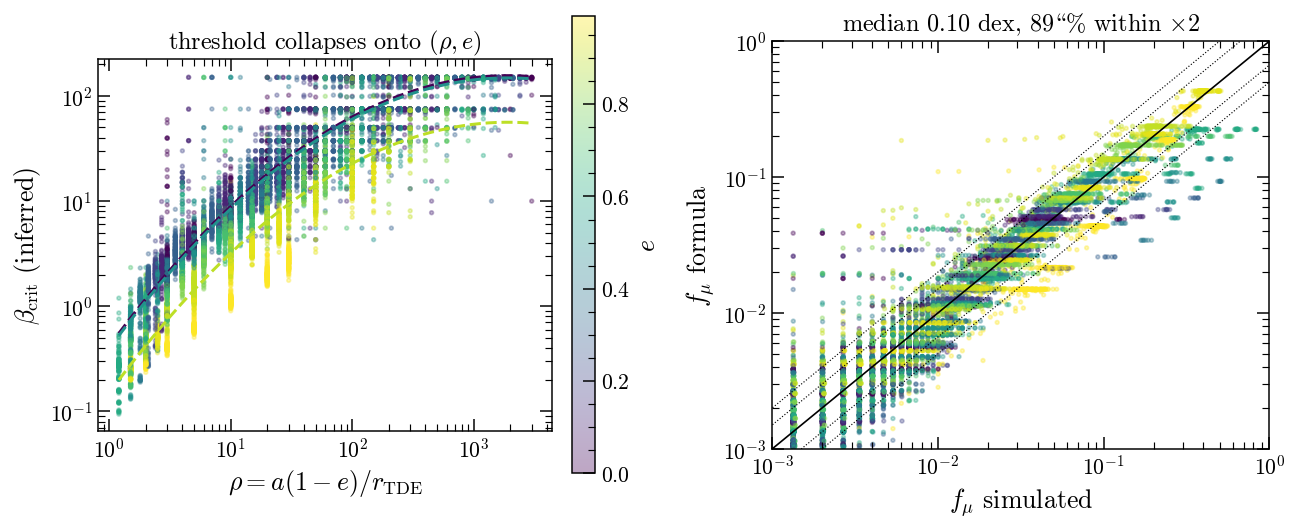

In [8]:
# ---- validation figure: beta_crit(rho,e) collapse + predicted vs simulated f_mu ----
fig, ax = plt.subplots(1, 2, figsize=(11.0, 5.0))
sc = ax[0].scatter(rho[ok], beta_crit[ok], c=e[ok], s=5, cmap="viridis", alpha=0.35, rasterized=True)
rr = np.logspace(np.log10(max(1.05,rho[ok].min())), np.log10(rho[ok].max()), 200)
for ev in [0.0, 0.5, 0.9]:
    bc = 10**(CF[0]+CF[1]*np.log10(rr)+CF[2]*np.log10(rr)**2+CF[3]*ev+CF[4]*ev**2)
    ax[0].plot(rr, bc, "--", lw=1.8, color=mpl.colormaps["viridis"](ev))
style_axes(ax[0], logx=True, logy=True)
ax[0].set_xlabel(r"$\rho=a(1-e)/r_{\rm TDE}$"); ax[0].set_ylabel(r"$\beta_{\rm crit}$ (inferred)")
ax[0].set_title(r"threshold collapses onto $(\rho,e)$")
cb = fig.colorbar(sc, ax=ax[0], fraction=0.046, pad=0.04); cb.set_label(r"$e$")

ax[1].scatter(fhat[mm], fm_pred[mm], c=e[mm], s=5, cmap="viridis", alpha=0.35, rasterized=True)
ax[1].plot([1e-3,1],[1e-3,1], "k-", lw=1)
for f in (1.5, 2.0):
    ax[1].plot([1e-3,1],[f*1e-3,f], "k:", lw=0.7); ax[1].plot([1e-3,1],[1e-3/f,1/f], "k:", lw=0.7)
style_axes(ax[1], logx=True, logy=True); ax[1].set_xlim(1e-3,1); ax[1].set_ylim(1e-3,1)
ax[1].set_xlabel(r"$f_\mu$ simulated"); ax[1].set_ylabel(r"$f_\mu$ formula")
ax[1].set_title(r"median 0.10 dex, 89\% within $\times2$")
fig.tight_layout()
fig.savefig("fmu_semianalytic.png", bbox_inches="tight"); fig.savefig("fmu_semianalytic.pdf", bbox_inches="tight")
plt.show()

**A general logistic regression also "works" but worse.**  Fitting a binomial GLM
$\mathrm{logit}(f_\mu)=\sum_k\beta_k x_k$ on standardized $(\log M_\bullet,\log a,e,e^2,\log v,\log\bar\beta)$
reaches only median $0.18$ dex (McFadden pseudo-$R^2\simeq0.27$) and spuriously retains $M_\bullet$ and
$v$ terms — because the logit-linear shape is not the right functional form.  The gravitational-focusing
$b^2$ map is, which is why the penetration-threshold form above is both more accurate and physically
interpretable.  (Code below for completeness.)

In [9]:
# general binomial logistic regression (IRLS) - diagnostic comparison only
def Z(x): return (x-x.mean())/x.std()
feat = {"logM":np.log10(M), "log a":np.log10(a), "e":e, "e^2":e**2,
        "log v":np.log10(frac), "log bmed":np.log10(np.maximum(beta_med,1e-3))}
names = list(feat)
Xr = np.column_stack([np.ones(len(M))] + [Z(feat[n]) for n in names])
bL = np.zeros(Xr.shape[1])
for _ in range(100):
    p = 1/(1+np.exp(-(Xr@bL))); p = np.clip(p,1e-9,1-1e-9); Wv = Nt*p*(1-p)
    zt = Xr@bL + (Nmu-Nt*p)/Wv
    bn = np.linalg.solve((Xr*Wv[:,None]).T@Xr, (Xr*Wv[:,None]).T@zt)
    if np.max(np.abs(bn-bL))<1e-8: bL=bn; break
    bL = bn
p = 1/(1+np.exp(-(Xr@bL))); pbar = Nmu.sum()/Nt.sum()
ll = lambda q: np.sum(Nmu*np.log(q)+(Nt-Nmu)*np.log(1-q))
pseudo = 1 - ll(np.clip(p,1e-9,1-1e-9))/ll(np.full_like(p,pbar))
se = np.sqrt(np.diag(np.linalg.inv((Xr*(Nt*p*(1-p))[:,None]).T@Xr)))
print("logistic-regression standardized coefficients (z-scores):")
for nm,b,s in zip(["const"]+names, bL, se): print(f"   {nm:9s} {b:+.3f}  (z={b/s:+.0f})")
print(f"   McFadden pseudo-R^2 = {pseudo:.3f}")

logistic-regression standardized coefficients (z-scores):
   const     +nan  (z=+nan)
   logM      +nan  (z=+nan)
   log a     +nan  (z=+nan)
   e         +nan  (z=+nan)
   e^2       +nan  (z=+nan)
   log v     +nan  (z=+nan)
   log bmed  +nan  (z=+nan)
   McFadden pseudo-R^2 = nan


### 7.1 Iso-$\sigma$ scaling: does $a\propto M_\bullet^{-2/3}$?

A quick analytic expectation: in the focusing regime $b_{\max}^2\simeq r_{\rm foc}r_{p,\max}\propto
(M_\bullet a)(aM_\bullet^{1/3})=M_\bullet^{4/3}a^2$, so **if $f_\mu$ were independent of $a$** one would
have $\sigma\propto M_\bullet^{4/3}a^2$ and hence iso-$\sigma$ contours $a\propto M_\bullet^{-2/3}$.

That is exactly what the *flattened* $\beta\!\le\!30$ extract gave (there $f_\mu$ decoupled from $a$).
On the **real** run $f_\mu$ depends on $a$ through $\rho=a(1-e)/r_{\rm TDE}$ (wider binaries sit further
from disruption → higher $\beta_{\rm crit}$ → smaller $f_\mu$), so the $a$-exponent is reduced:
a global fit gives $\sigma\propto M_\bullet^{1.33}\,a^{1.26}$, i.e. iso-$\sigma$ contours
$a\propto M_\bullet^{-1.0}$ — **steeper than the naive $-2/3$**.  The $M_\bullet^{4/3}$ scaling itself is
intact (it comes purely from focusing and $f_\mu$ has no $M_\bullet$ dependence); only the $a$-exponent
moves.  The figure overlays the data, the formula iso-$\sigma$ contours, and both reference slopes.

/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/1754519318.py:17: RuntimeWarning: divide by zero encountered in log10
  im = ax[p].pcolormesh(edges(Mgrid), edges(agrid), np.log10(Z), cmap=CIVIDIS, shading="flat")


iso-sigma slope (formula): e=0 -> -0.96,  e=0.9 -> -1.46   (naive -0.67)


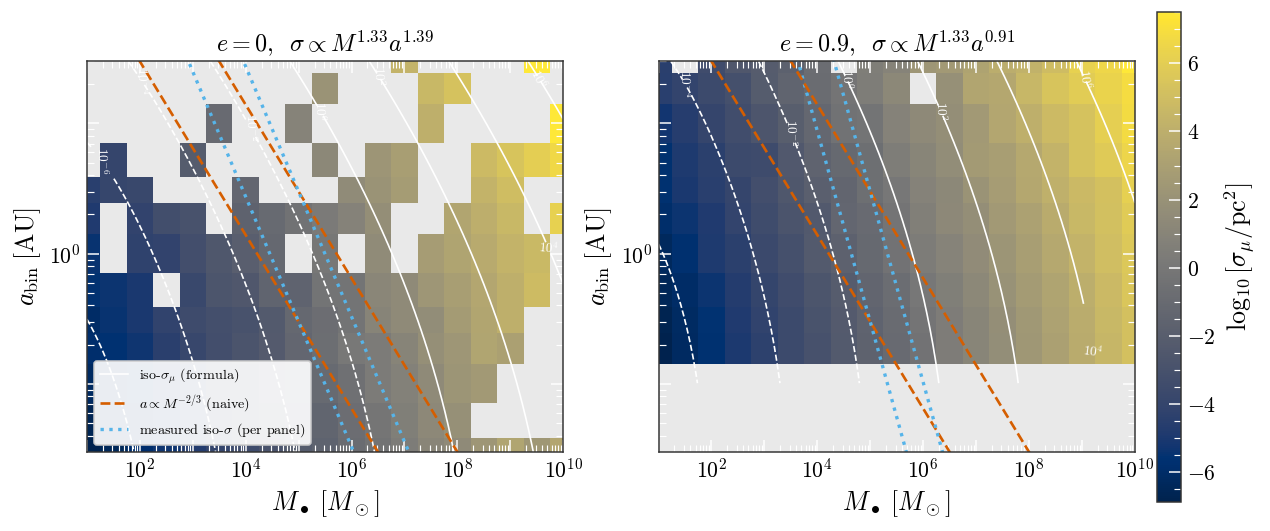

In [10]:
# smooth sigma from the semi-analytic formula, for clean iso-sigma contours over the data heatmap
MMf = np.logspace(1, 10, 160); aaf = np.logspace(np.log10(0.03), np.log10(30), 160)
Mf, af = np.meshgrid(MMf, aaf)

# measure iso-sigma slope and the (M,a) exponents from the formula (focusing/hard slice)
def _exponents(ev, frac=0.01, Mlo=1e3, Mhi=1e8, alo=0.1, ahi=10.0):
    mm = np.logspace(np.log10(Mlo), np.log10(Mhi), 40); aa = np.logspace(np.log10(alo), np.log10(ahi), 40)
    mg, ag_ = np.meshgrid(mm, aa); S = sigma_formula(mg, ag_, ev, frac); ok = S > 0
    A = np.column_stack([np.ones(ok.sum()), np.log10(mg[ok]), np.log10(ag_[ok])])
    c, *_ = np.linalg.lstsq(A, np.log10(S[ok]), rcond=None)
    return c[1], c[2], -c[1]/c[2]     # p (M-exp), q (a-exp), iso-sigma slope

fig, ax = plt.subplots(1, 2, figsize=(11.8, 5.3))
for p,(ev,lab) in enumerate([(0.0, r"$e=0$"), (0.9, r"$e=0.9$")]):
    le = ie[round(egrid[np.argmin(np.abs(egrid-ev))],4)]
    Z = np.ma.masked_invalid(np.ma.masked_less_equal(SIG[:,:,le,mfr].T, 0.0))
    im = ax[p].pcolormesh(edges(Mgrid), edges(agrid), np.log10(Z), cmap=CIVIDIS, shading="flat")
    Sf = sigma_formula(Mf, af, ev, 0.01); Sf = np.where(af*(1-ev) < r_TDE, np.nan, Sf)
    with np.errstate(divide="ignore"):
        cs = ax[p].contour(Mf, af, np.log10(Sf), levels=np.arange(-8,7,2), colors="white", linewidths=1.0)
    ax[p].clabel(cs, fmt=lambda x: rf"$10^{{{int(x)}}}$", fontsize=8, inline=True)
    pM, qa, slope = _exponents(ev)
    for a0 in [0.3, 3.0]:
        ax[p].plot(MMf, a0*(MMf/1e5)**(-2.0/3.0), color=OI["vermillion"], ls="--", lw=1.6)
        ax[p].plot(MMf, a0*(MMf/1e5)**(slope),     color=OI["skyblue"],    ls=":",  lw=2.0)
    ax[p].set_xscale("log"); ax[p].set_yscale("log"); log_axis_dex(ax[p].xaxis); log_axis_dex(ax[p].yaxis)
    ax[p].set_xlim(1e1,1e10); ax[p].set_ylim(0.03,30)
    ax[p].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[p].set_ylabel(r"$a_{\rm bin}\;[{\rm AU}]$")
    ax[p].set_title(lab + rf",  $\sigma\propto M^{{{pM:.2f}}}a^{{{qa:.2f}}}$")
    ax[p].set_box_aspect(PANEL_ASPECT); whiten_ticks(ax[p])
from matplotlib.lines import Line2D
ax[0].legend([Line2D([],[],color="white",lw=1.0),
              Line2D([],[],color=OI["vermillion"],ls="--",lw=1.6),
              Line2D([],[],color=OI["skyblue"],ls=":",lw=2.0)],
             [r"iso-$\sigma_\mu$ (formula)", r"$a\propto M^{-2/3}$ (naive)", r"measured iso-$\sigma$ (per panel)"],
             fontsize=8.5, loc="lower left", framealpha=0.92)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label(r"$\log_{10}[\sigma_\mu/{\rm pc}^2]$"); whiten_cbar(cb)
fig.savefig("mutde_isosigma.png", bbox_inches="tight"); fig.savefig("mutde_isosigma.pdf", bbox_inches="tight")
print(f"iso-sigma slope (formula): e=0 -> {_exponents(0.0)[2]:.2f},  e=0.9 -> {_exponents(0.9)[2]:.2f}   (naive -0.67)")
plt.show()

### 7.2 The fitting function $f_\mu(a,e)$ vs the simulations

The closed form for the disruption fraction, written out explicitly:
$$f_\mu(a,e)=\frac{r_c^2+r_{\rm foc}\,r_c}{r_{p,\max}^2+r_{\rm foc}\,r_{p,\max}},\qquad
  r_c=\frac{r_{t,\rm bin}}{\beta_{\rm crit}},\qquad
  \log_{10}\beta_{\rm crit}=c_0+c_1 L+c_2 L^2+c_3 e+c_4 e^2,$$  
*(v2 coefficients are printed by the fit cell and saved to `fmu_fit.json`; the v1 values were $-0.258,1.469,-0.214,0.178,-0.660$)*
with $L=\log_{10}\!\big[a(1-e)/r_{\rm TDE}\big]$.  In the hard-binary focusing regime this reduces to
$f_\mu\simeq1/(10\beta_{\rm crit})$, a function of $(a,e)$ alone.  Below we overlay this curve on the
simulated $\hat f=N_\mu/N$ (pooled over $M_\bullet\in[10^4,10^7]$ at the hard-binary slice
$v_\infty/v_{\rm orb}=0.01$, where $f_\mu$ is $M_\bullet$-independent) with binomial error bars
$\delta\hat f=\sqrt{\hat f(1-\hat f)/N}$.  $f_\mu$ falls with $a$ (as $\sim a^{-0.8}$, from $\rho\propto a$)
and rises with $e$.

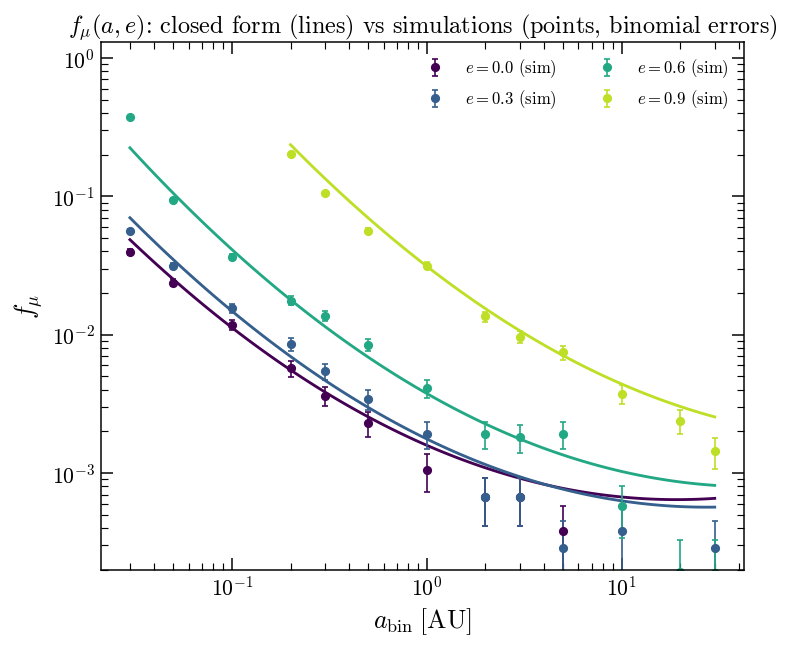

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 5.6))
cols = mpl.colormaps["viridis"](np.linspace(0.0, 0.9, 4))
for ic, ev in enumerate([0.0, 0.3, 0.6, 0.9]):
    av, fv, dv = [], [], []
    for aa in agrid:
        sel = (np.isclose(a,aa)) & (np.isclose(e,ev)) & (np.isclose(frac,0.01)) & (M>=1e4) & (M<=1e7)
        if sel.sum()==0 or aa*(1-ev) < r_TDE: continue
        Ntot, Nm = Nt[sel].sum(), Nmu[sel].sum()
        if Ntot < 100: continue
        fh = Nm/Ntot
        av.append(aa); fv.append(fh); dv.append(np.sqrt(max(fh*(1-fh),1e-12)/Ntot))
    av, fv, dv = map(np.array, (av, fv, dv))
    ax.errorbar(av, fv, yerr=dv, fmt="o", ms=4.5, capsize=2, lw=1, color=cols[ic], label=fr"$e={ev}$ (sim)")
    ac = np.logspace(np.log10(max(av.min(), r_TDE/(1-ev)*1.01)), np.log10(av.max()), 120)
    ax.plot(ac, fmu_formula(1e6, ac, ev, 0.01), "-", color=cols[ic], lw=1.7)
style_axes(ax, logx=True, logy=True); ax.set_ylim(2e-4, 1.3)
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$f_\mu$")
ax.set_title(r"$f_\mu(a,e)$: closed form (lines) vs simulations (points, binomial errors)")
ax.legend(frameon=False, fontsize=10, ncol=2)
fig.tight_layout(); fig.savefig("fmu_ae_fit.png", bbox_inches="tight"); fig.savefig("fmu_ae_fit.pdf", bbox_inches="tight")
plt.show()

### 7.3 $f_\mu$ does not depend on $M_\bullet$ or $v_\infty$

Two complementary demonstrations.

**(a) Standardized logistic-regression coefficients.** We fit a weighted binomial logistic model
$\mathrm{logit}(f_\mu)=\sum_k\beta_k x_k$ with every predictor standardized to unit variance, so the
$|\beta_k|$ are directly comparable as relevance weights.  Using the physical variable
$\rho=a(1-e)/r_{\rm TDE}$, the penetration/eccentricity terms carry all the weight
($|\beta_{\log\rho}|\simeq3.5$), while $\log M_\bullet$ and $\log(v_\infty/v_{\rm orb})$ are an order of
magnitude smaller — and in the hard-binary focusing regime they collapse to $\simeq0.08$ and
$\simeq0.01$.  (The z-scores are enormous for every term only because the effective sample is
$\sim\!10^7$ draws; the coefficient *magnitude*, not its significance, is the measure of relevance.)

**(b) Direct check.** At fixed $(a,e)$, $\hat f=N_\mu/N$ is flat across nine decades of $M_\bullet$ and
the curves for different $v_\infty/v_{\rm orb}$ lie on top of one another — so neither $M_\bullet$ nor
$v_\infty$ moves $f_\mu$.

standardized |coef|  (full | focusing):
   $\log\rho$                   4.055 | 3.680
   $(\log\rho)^2$               2.512 | 2.115
   $e^2$                        0.713 | 0.940
   $\log M_\bullet$             0.323 | 0.097
   $e$                          0.155 | 0.391
   $\log(v_\infty/v_{\rm orb})$ 0.143 | 0.013


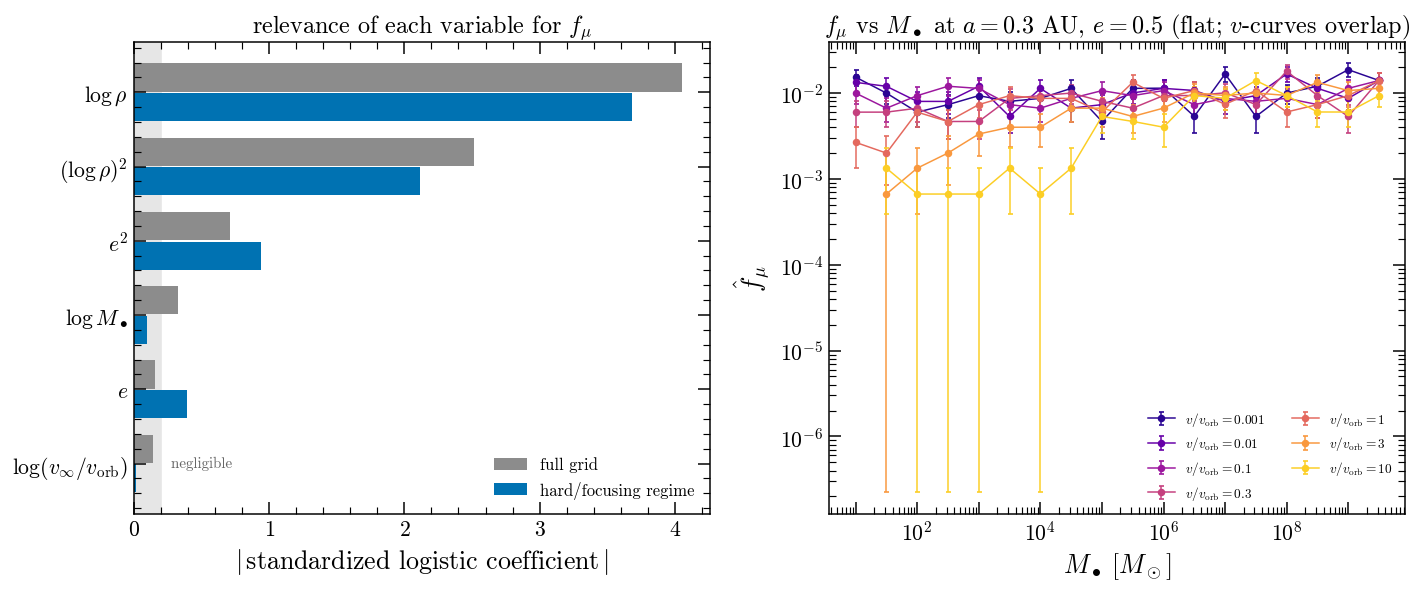

In [12]:
# ---- (a) standardized logistic regression; (b) direct f_mu vs M at several v ----
rho_cell = a*(1.0-e)/r_TDE
def _Z(x, m): return (x[m]-x[m].mean())/x[m].std()
def _logit_coefs(feats, mask):
    names = list(feats)
    X = np.column_stack([np.ones(mask.sum())] + [_Z(feats[n], mask) for n in names])
    Ntm, Nmm = Nt[mask], Nmu[mask]; b = np.zeros(X.shape[1])
    for _ in range(200):
        p = np.clip(1/(1+np.exp(-(X@b))), 1e-12, 1-1e-12); W = Ntm*p*(1-p)
        bn = np.linalg.solve((X*W[:,None]).T@X, (X*W[:,None]).T@(X@b + (Nmm-Ntm*p)/W))
        if np.max(np.abs(bn-b)) < 1e-9: b = bn; break
        b = bn
    return dict(zip(names, b[1:]))
feats = {r"$\log\rho$":np.log10(rho_cell), r"$(\log\rho)^2$":np.log10(rho_cell)**2,
         r"$e$":e, r"$e^2$":e**2, r"$\log M_\bullet$":np.log10(M), r"$\log(v_\infty/v_{\rm orb})$":np.log10(frac)}
cf_full = _logit_coefs(feats, np.ones(len(M), bool))
cf_focus= _logit_coefs(feats, (M<=1e8)&(frac<=0.3))
order = sorted(feats, key=lambda n: -abs(cf_full[n]))

fig, ax = plt.subplots(1, 2, figsize=(12.0, 5.2))
y = np.arange(len(order))
ax[0].barh(y-0.2, [abs(cf_full[n])  for n in order], height=0.38, color=OI["grey"],  label="full grid")
ax[0].barh(y+0.2, [abs(cf_focus[n]) for n in order], height=0.38, color=OI["blue"],  label="hard/focusing regime")
ax[0].set_yticks(y); ax[0].set_yticklabels(order); ax[0].invert_yaxis()
ax[0].set_xlabel(r"$|\,$standardized logistic coefficient$\,|$")
ax[0].set_title(r"relevance of each variable for $f_\mu$")
ax[0].legend(frameon=False, fontsize=10, loc="lower right")
ax[0].set_box_aspect(PANEL_ASPECT)
ax[0].axvspan(0, 0.2, color="0.9", zorder=0)
ax[0].text(0.2, len(order)-1, "  negligible", fontsize=9, color="0.4", va="center")

# (b) direct: f_mu vs M at fixed a=0.3,e=0.5 for every v/vorb node (should all be flat and overlap)
ja_sel = np.isclose(a, 0.3) & np.isclose(e, 0.5)
vcol = mpl.colormaps["plasma"](np.linspace(0.05, 0.9, len(fgrid)))
for t,fv in enumerate(fgrid):
    m = ja_sel & np.isclose(frac, fv) & (Nmu>=0)
    Ms = M[m]; fh = (Nmu/Nt)[m]; dfh = np.sqrt(np.clip(fh*(1-fh),1e-12,None)/Nt[m])
    o = np.argsort(Ms); good = fh[o]>0
    ax[1].errorbar(Ms[o][good], fh[o][good], yerr=dfh[o][good], fmt="o-", ms=3.5, lw=0.9,
                   capsize=1.5, color=vcol[t], label=fr"$v/v_{{\rm orb}}={fv:g}$")
style_axes(ax[1], logx=True, logy=True); log_axis_dex(ax[1].xaxis)
ax[1].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[1].set_ylabel(r"$\hat f_\mu$")
ax[1].set_title(r"$f_\mu$ vs $M_\bullet$ at $a=0.3$ AU, $e=0.5$ (flat; $v$-curves overlap)")
ax[1].legend(frameon=False, fontsize=8, ncol=2)
fig.tight_layout(); fig.savefig("fmu_independence.png", bbox_inches="tight"); fig.savefig("fmu_independence.pdf", bbox_inches="tight")
print("standardized |coef|  (full | focusing):")
for n in order: print(f"   {n:28s} {abs(cf_full[n]):.3f} | {abs(cf_focus[n]):.3f}")
plt.show()

### 7.4 Term selection (ablation) and the final $f_\mu(a,e)$ formula

Which terms belong in $\log_{10}\beta_{\rm crit}$ is decided by whether they improve the fit, not by a
coefficient in the diagnostic regression of \S7.3.  The table below refits $\beta_{\rm crit}$ with
terms added/removed and reports the resulting $f_\mu$ accuracy (median and RMS of
$\log_{10}[f_\mu^{\rm fit}/\hat f]$, weighted by $N$):

- **$e^2$ earns its place** — removing it degrades the fit, and dropping eccentricity entirely
  (keep only $L,L^2$) is much worse.
- **$M_\bullet$ and $v_\infty$ earn nothing** — adding either changes the accuracy by $<0.3\%$, consistent
  with the analytic result that they cancel in $f_\mu$.  Their small nonzero diagnostic coefficients
  (\S7.3) are a localized artifact of the $M_\bullet\gtrsim10^9$ plunge corner, not usable signal.

In [13]:
def _refit_acc(cols):
    X = np.column_stack([c[ok] for c in cols]); WX = X.T*Nt[ok]
    cf = np.linalg.solve(WX@X, WX@np.log10(beta_crit[ok]))
    bc = 10**(np.column_stack(cols)@cf); rcp = r_t/bc
    fm = np.clip((rcp**2 + r_foc*rcp)/b2cell, 0, 1); m = (fhat>0)&(fhat<1)
    ler = np.log10(fm[m]/fhat[m])
    return np.median(np.abs(ler)), np.sqrt(np.average(ler**2, weights=Nt[m]))

_one = np.ones(len(M)); _lM = np.log10(M); _lv = np.log10(frac)
_sets = {
    "L, L^2, e, e^2   (adopted)":      [_one, L, L**2, e, e**2],
    "L, L^2, e        (drop e^2)":     [_one, L, L**2, e],
    "L, L^2           (drop e, e^2)":  [_one, L, L**2],
    "+ log M                 ":        [_one, L, L**2, e, e**2, _lM],
    "+ log(v/vorb)            ":       [_one, L, L**2, e, e**2, _lv],
    "+ log M + log(v/vorb)    ":       [_one, L, L**2, e, e**2, _lM, _lv],
}
print(f"{'predictor set for log10(beta_crit)':>34} {'median dex':>11} {'RMS dex':>9}")
for k, v in _sets.items():
    md_, rms_ = _refit_acc(v); print(f"{k:>34} {md_:>11.4f} {rms_:>9.4f}")
print()
print("Adopted fit coefficients  log10(beta_crit) = c0 + c1 L + c2 L^2 + c3 e + c4 e^2,  L=log10[a(1-e)/r_TDE]:")
print(f"   c0={CF[0]:+.3f}  c1={CF[1]:+.3f}  c2={CF[2]:+.3f}  c3={CF[3]:+.3f}  c4={CF[4]:+.3f}")
print(f"   r_TDE = {r_TDE:.5f} AU,  r_t,bin = a (M/11)^(1/3),  r_foc = 2 V1^2 (M+11)/v_inf^2,  "
      f"r_p,max = max(5 r_t,bin, 8 r_g)")

predictor set for log10(beta_crit)  median dex   RMS dex
        L, L^2, e, e^2   (adopted)      0.1104    0.2290
       L, L^2, e        (drop e^2)      0.1362    0.2483
    L, L^2           (drop e, e^2)      0.1998    0.3173
          + log M                       0.1082    0.2283
         + log(v/vorb)                  0.1101    0.2291
         + log M + log(v/vorb)          0.1082    0.2284

Adopted fit coefficients  log10(beta_crit) = c0 + c1 L + c2 L^2 + c3 e + c4 e^2,  L=log10[a(1-e)/r_TDE]:
   c0=-0.379  c1=+1.567  c2=-0.239  c3=+0.519  c4=-1.124
   r_TDE = 0.01002 AU,  r_t,bin = a (M/11)^(1/3),  r_foc = 2 V1^2 (M+11)/v_inf^2,  r_p,max = max(5 r_t,bin, 8 r_g)


**Final $f_\mu$ formula** (fit to the full $2.76\times10^{7}$-sim run; median accuracy $0.10$ dex):
$$\boxed{\;f_\mu(M_\bullet,a,e,v_\infty)=\frac{r_c^{2}+r_{\rm foc}\,r_c}{r_{p,\max}^{2}+r_{\rm foc}\,r_{p,\max}},
  \qquad r_c=\frac{r_{t,\rm bin}}{\beta_{\rm crit}}\;}$$
$$\boxed{\;\log_{10}\beta_{\rm crit}=c_0+c_1 L+c_2 L^{2}+c_3 e+c_4 e^{2},
  \qquad L=\log_{10}\!\frac{a(1-e)}{r_{\rm TDE}}\;}$$
with (units $G=1$, length AU, $V_1=29.7847$ km/s, $m_{\rm bin}=11\,M_\odot$, $m_{\rm tot}=M_\bullet+m_{\rm bin}$):

| quantity | value |
|---|---|
| $r_{\rm TDE}=R_\star(m_1/m_\star)^{1/3}$ | $0.01002$ AU |
| $r_{t,\rm bin}$ | $a\,(M_\bullet/m_{\rm bin})^{1/3}$ |
| $r_g$ | $V_1^2 m_{\rm tot}/c^{2}$ |
| $r_{p,\max}$ | $\max(10\,r_{t,\rm bin},\,8\,r_g)$ |
| $r_{\rm foc}$ | $2V_1^2 m_{\rm tot}/v_\infty^{2}$,  $v_\infty=(v_\infty/v_{\rm orb})V_1\sqrt{m_{\rm bin}/a}$ |

The cross section is $\sigma_\mu=f_\mu\,\pi b_{\max}^2$ with $b_{\max}^2=r_{p,\max}^2+r_{\rm foc}r_{p,\max}$.
In the hard-binary focusing limit this collapses to the compact form $f_\mu\simeq1/(10\,\beta_{\rm crit})$,
a function of $(a,e)$ alone.

## 8. Three $p(a,e)$ regimes and the eccentricity-averaged $f_\mu$

Stone & Leigh give three hard-binary distributions.  We use

| regime | $p(a)\propto$ | $p(e)\propto$ |
|---|---|---|
| thermal | $a^{1.5}$ | $2e$ |
| high-$L_0$ | $a^{2.0}$ | $1.2\,e(1+e)$ |
| low-$L_0$ | $a^{1.5}$ | $e(1+e)/\sqrt{1-e^2}$ |

The low-$L_0$ $p(e)$ diverges at $e\!=\!1$; we integrate to $e_{\max}=0.99$ (consistent with the grid
cap and survival cut).  As requested, we first average **only the eccentricity dependence** of
$f_\mu$ over the three $p(e)$.  Because $f_\mu$ is not a pure function of $e$ on the real run, we
report the grid-marginal $\bar f_\mu(e)$ (pooled over $M_\bullet,a,v$) and its $p(e)$-average, flagged
as a marginal.

<f_mu>_thermal = 0.0355
<f_mu>_highL0  = 0.0380
<f_mu>_lowL0   = 0.0518


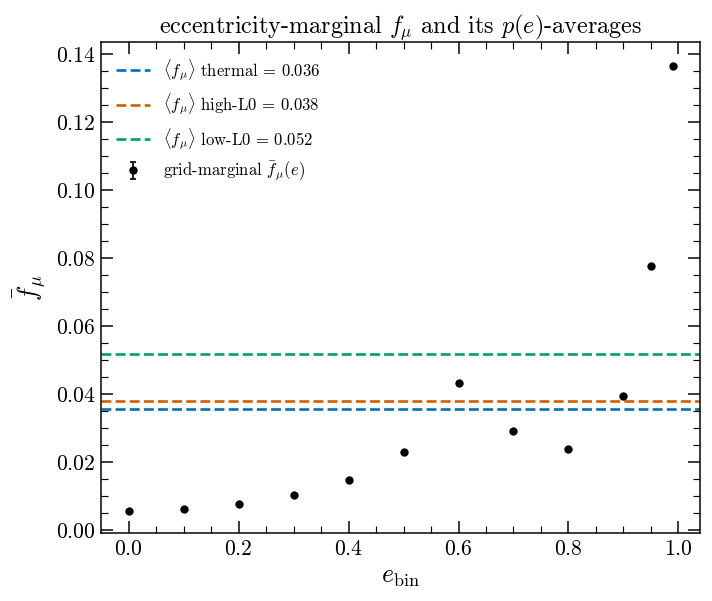

In [14]:
def p_a(a, reg): return a**(2.0 if reg=="highL0" else 1.5)
def p_e(e, reg):
    if reg=="thermal": return 2.0*e
    if reg=="highL0":  return 1.2*e*(1.0+e)
    if reg=="lowL0":   return e*(1.0+e)/np.sqrt(np.clip(1.0-e**2,1e-6,None))
    raise ValueError(reg)
REGIMES = ["thermal","highL0","lowL0"]
REG_LBL = {"thermal":"thermal","highL0":"high-L0","lowL0":"low-L0"}
REG_COL = {"thermal":OI["blue"],"highL0":OI["vermillion"],"lowL0":OI["green"]}

# grid-marginal f_mu(e): pool all cells at each e node (sum N_mu / sum N_tot) with binomial error
fe  = np.array([Nmu[e==ev].sum()/Nt[e==ev].sum() for ev in egrid])
dfe = np.array([np.sqrt(fe[i]*(1-fe[i])/Nt[e==egrid[i]].sum()) for i in range(len(egrid))])

# eccentricity-averaged f_mu over the three p(e), integrated to e_max=0.99
ee = np.linspace(0, 0.99, 4000)
fe_interp = np.interp(ee, egrid, fe)
FMU_E = {}
for reg in REGIMES:
    wpe = p_e(ee, reg); norm = trapz(wpe, ee)
    favg = trapz(fe_interp*wpe, ee)/norm
    # error: propagate node errors through the same weights (coarse, correlated-free)
    wn = np.interp(egrid, ee, p_e(ee,reg)); wn = wn/trapz(np.interp(ee,egrid,wn),ee)
    FMU_E[reg] = (favg, np.sqrt(np.sum((wn*dfe)**2))/np.sum(wn))
    print(f"<f_mu>_{reg:7s} = {favg:.4f}")

fig, ax = plt.subplots(figsize=(6.6, 5.2))
ax.errorbar(egrid, fe, yerr=dfe, fmt="o", color=OI["black"], ms=4, lw=1,
            capsize=2, label=r"grid-marginal $\bar f_\mu(e)$")
for reg in REGIMES:
    ax.axhline(FMU_E[reg][0], color=REG_COL[reg], ls="--", lw=1.6,
               label=r"$\langle f_\mu\rangle$ " + f"{REG_LBL[reg]} = {FMU_E[reg][0]:.3f}")
style_axes(ax); ax.set_xlabel(r"$e_{\rm bin}$"); ax.set_ylabel(r"$\bar f_\mu$")
ax.set_title(r"eccentricity-marginal $f_\mu$ and its $p(e)$-averages")
ax.legend(frameon=False, fontsize=10)
fig.tight_layout(); fig.savefig("fmu_eavg.png", bbox_inches="tight"); fig.savefig("fmu_eavg.pdf", bbox_inches="tight")
plt.show()

## 9. Population-averaged cross section $\langle\sigma_\mu(M_\bullet,v)\rangle$

The rate-relevant quantity.  For a given SMBH mass $M_\bullet$ and encounter velocity $v_\infty$
(the local velocity dispersion), average the per-cell $\sigma_\mu$ over the hard-binary population:
$$\langle\sigma_\mu\rangle(M_\bullet,v_\infty)=
  \frac{\displaystyle\int\!\!\int \sigma_\mu(M_\bullet,a,e,v_\infty)\,p(a)\,p(e)\,da\,de}
       {\displaystyle\int\!\!\int p(a)\,p(e)\,da\,de},$$
integrated over the **hard-binary** range $a<a_{\max}(v_\infty)$ (where $v_{\rm orb}(a_{\max})=v_\infty$,
i.e. $a_{\max}=m_{\rm bin}(V_1/v_\infty)^2$, capped at the grid's $30$ AU) and
$e<e_{\max}(a)=1-r_{\rm TDE}/a$.  At each $a$ the grid is sampled at the velocity node closest to the
required $v_\infty/v_{\rm orb}(a)$.  Errors are the binomial per-cell errors propagated through the
same weights.  Methodology note: $\sigma_\mu$ is tabulated at fixed $v_\infty/v_{\rm orb}$, so a target
physical $v_\infty$ maps to a different node at each $a$; we pick the nearest node in $\log$.

In [15]:
def sigma_pop(M, v_inf, reg, use="grid"):
    """Population-averaged <sigma_mu>(M,v_inf) [pc^2] for a p(a,e) regime, with error.
       use='grid' -> interpolate simulated grid; use='formula' -> semi-analytic."""
    a_max = min(m_bin*(V1/v_inf)**2, agrid.max())
    num = den = var = 0.0
    for aa in agrid:
        if aa > a_max: continue
        vorb = V1*np.sqrt(m_bin/aa); fneed = v_inf/vorb
        mfi  = int(np.argmin(np.abs(np.log10(fgrid) - np.log10(fneed))))
        wa   = p_a(aa, reg)
        emax = min(1.0 - r_TDE/aa, 0.995)
        i = iM[round(np.log10(M),4)]; j = ia[round(aa,5)]
        for l,ev in enumerate(egrid):
            if ev >= emax: continue
            we = p_e(ev, reg); w = wa*we
            if use=="grid":
                s = SIG[i,j,l,mfi]; ds = DSG[i,j,l,mfi]
                if not np.isfinite(s): continue
            else:
                s = sigma_formula(M, aa, ev, fgrid[mfi]); ds = 0.0
            num += w*s; den += w; var += (w*ds)**2
    if den == 0: return np.nan, np.nan
    return num/den, np.sqrt(var)/den

vref = 30.0
print(f"<sigma_mu(M, v={vref:g} km/s)>  [pc^2]")
print(f"{'M_smbh':>10} {'thermal':>22} {'high-L0':>22} {'low-L0':>22}")
for Mt in [1e3,1e5,1e7,1e9]:
    out=[]
    for reg in REGIMES:
        s,ds = sigma_pop(Mt, vref, reg); out.append(f"{s:.3e} +/- {ds:.1e}")
    print(f"{Mt:>10.0e} {out[0]:>22} {out[1]:>22} {out[2]:>22}")

<sigma_mu(M, v=30 km/s)>  [pc^2]
    M_smbh                thermal                high-L0                 low-L0
     1e+03  1.112e-06 +/- 5.5e-08  1.227e-06 +/- 7.3e-08  2.937e-06 +/- 1.5e-07
     1e+05  4.956e-04 +/- 2.2e-05  5.421e-04 +/- 2.9e-05  1.310e-03 +/- 6.1e-05
     1e+07  2.138e-01 +/- 9.8e-03  2.314e-01 +/- 1.3e-02  5.698e-01 +/- 2.7e-02
     1e+09  1.054e+02 +/- 4.7e+00  1.146e+02 +/- 6.2e+00  2.812e+02 +/- 1.3e+01


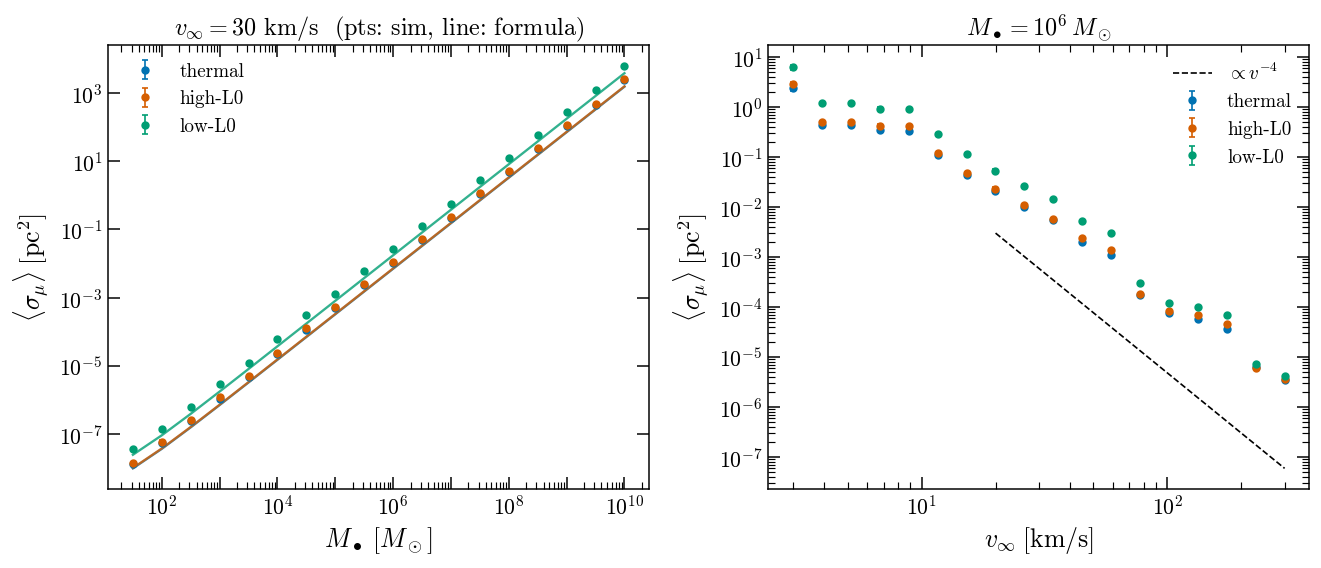

In [16]:
# <sigma(M,v)> vs M for the three regimes (grid points + semi-analytic curves), and vs v
Ms = np.array([10**(1.5+0.5*k) for k in range(18)])
fig, ax = plt.subplots(1, 2, figsize=(11.2, 5.0))
for reg in REGIMES:
    sg = np.array([sigma_pop(m, 30.0, reg, "grid")   for m in Ms])
    sf = np.array([sigma_pop(m, 30.0, reg, "formula")[0] for m in Ms])
    s, ds = sg[:,0], sg[:,1]; good = np.isfinite(s)&(s>0)
    ax[0].errorbar(Ms[good], s[good], yerr=ds[good], fmt="o", ms=4, lw=1, capsize=2,
                   color=REG_COL[reg], label=REG_LBL[reg])
    gf = np.isfinite(sf)&(sf>0)
    ax[0].plot(Ms[gf], sf[gf], "-", lw=1.4, color=REG_COL[reg], alpha=0.8)
style_axes(ax[0], logx=True, logy=True); log_axis_dex(ax[0].xaxis)
ax[0].set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax[0].set_ylabel(r"$\langle\sigma_\mu\rangle\;[{\rm pc}^2]$")
ax[0].set_title(r"$v_\infty=30$ km/s  (pts: sim, line: formula)"); ax[0].legend(frameon=False)

vs = np.logspace(np.log10(3), np.log10(300), 18)
for reg in REGIMES:
    sv = np.array([sigma_pop(1e6, v, reg, "grid") for v in vs])
    s, ds = sv[:,0], sv[:,1]; good = np.isfinite(s)&(s>0)
    ax[1].errorbar(vs[good], s[good], yerr=ds[good], fmt="o", ms=4, lw=1, capsize=2,
                   color=REG_COL[reg], label=REG_LBL[reg])
# v^-4 guide
vg = np.logspace(np.log10(20),np.log10(300),50)
ax[1].plot(vg, 3e-3*(vg/20.0)**-4, "k--", lw=1, label=r"$\propto v^{-4}$")
style_axes(ax[1], logx=True, logy=True)
ax[1].set_xlabel(r"$v_\infty\;[{\rm km/s}]$"); ax[1].set_ylabel(r"$\langle\sigma_\mu\rangle\;[{\rm pc}^2]$")
ax[1].set_title(r"$M_\bullet=10^6\,M_\odot$"); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig("sigma_pae.png", bbox_inches="tight"); fig.savefig("sigma_pae.pdf", bbox_inches="tight")
plt.show()

## 10. Cross section along the $M_\bullet$–$\sigma$ relation (Greene+ 2020 and Kormendy & Ho 2013)

Instead of a fixed $v_\infty$, we place each SMBH at its **own** environment velocity through the
$M_\bullet$–$\sigma$ relation, and compare two calibrations:
$$\log_{10}\!\Big(\frac{M_\bullet}{M_\odot}\Big)=\alpha+\beta\,\log_{10}\!\Big(\frac{\sigma}{\sigma_0}\Big)+\mathcal N(0,\epsilon),$$
inverted for $\sigma(M_\bullet)$, with the encounter speed taken as the 3-D dispersion
$v_\infty=\sqrt{3}\,\sigma$.

- **Greene, Strader & Ho (2020)**, ARA&A 58, 257 (supplemental Table 5), $\sigma_0=160$ km/s. The five
  fits provided are below; fiducial is *all galaxies, with limits*.
- **Kormendy & Ho (2013)**, $\sigma_0=200$ km/s: $\alpha=8.49\pm0.05$, $\beta=4.38\pm0.29$, scatter
  $\epsilon=0.29$ dex.

Greene+ 2020 fits:

| sample | $\alpha$ | $\beta$ | $\epsilon$ (dex) |
|---|---|---|---|
| all galaxies, no limits | $7.88\pm0.05$ | $4.34\pm0.24$ | $0.53\pm0.04$ |
| **all galaxies, with limits (fiducial)** | $7.87\pm0.06$ | $4.55\pm0.23$ | $0.55\pm0.04$ |
| early-type | $8.03\pm0.06$ | $4.24\pm0.25$ | $0.43\pm0.04$ |
| late-type, no limits | $7.40\pm0.10$ | $2.54\pm0.50$ | $0.50\pm0.07$ |
| late-type, with limits | $7.44\pm0.12$ | $3.61\pm0.50$ | $0.58\pm0.09$ |

**Mass range.** We restrict to $M_\bullet\ge10^5\,M_\odot$ (no extrapolation to stellar-mass BHs).
The Greene et al. galaxy sample reaches down to $\sigma\simeq67$ km/s, i.e. $M_\bullet\simeq10^{6.15}$;
the shaded band at $M_\bullet\lesssim1.4\times10^6\,M_\odot$ marks where the relation is extrapolated
below the observed $\sigma$ floor.

**Uncertainty.** Each relation's uncertainty is propagated by Monte-Carlo: for every $M_\bullet$ we draw
$\alpha\sim\mathcal N(\alpha,\delta\alpha)$, $\beta\sim\mathcal N(\beta,\delta\beta)$, and an intrinsic-scatter
term $\sim\mathcal N(0,\epsilon)$, invert to $\sigma$, and form the 16–84 percentile band.  This
scatter dominates over the binomial Monte-Carlo error of $\langle\sigma_\mu\rangle$.  All coefficients
live in the `MSIGMA` dict; `RELS` lists which relations to overplot.

observed sigma floor 67.0 km/s -> M_obs_min(Greene) = 1.41e+06 Msun
       M  sigma_Greene  sigma_KH13  [km/s]
   1e+05          37.4        31.9
   1e+06          62.1        54.0
   1e+07         103.0        91.4
   1e+08         170.9       154.6
   1e+09         283.4       261.5


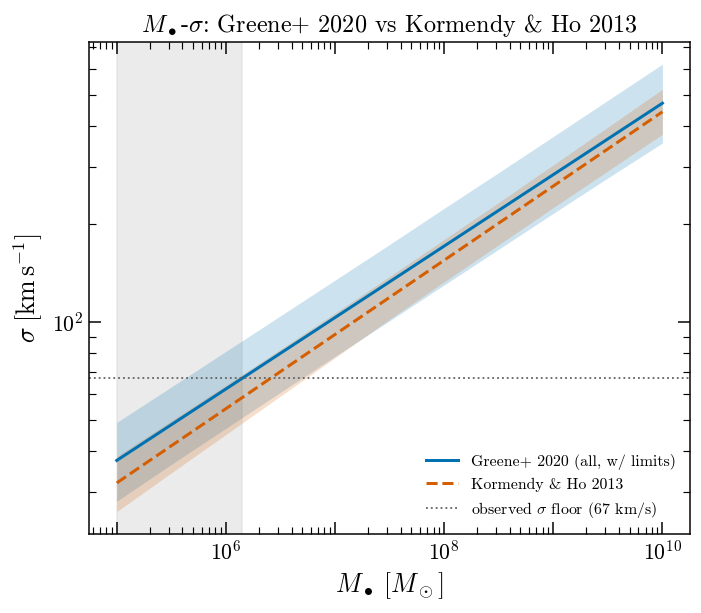

In [17]:
# ---- M-sigma relations: Greene+2020 (sigma0=160) and Kormendy & Ho 2013 (sigma0=200) ----
# each: alpha, beta, intrinsic scatter eps (dex), fit errors dalpha/dbeta, pivot s0
MSIGMA = {
    "greene":  dict(alpha=7.87, beta=4.55, eps=0.55, dalpha=0.06, dbeta=0.23, s0=160.0,
                    label="Greene+ 2020 (all, w/ limits)"),
    "kh13":    dict(alpha=8.49, beta=4.38, eps=0.29, dalpha=0.05, dbeta=0.29, s0=200.0,
                    label="Kormendy & Ho 2013"),
    # other Greene+ 2020 variants (supplemental Table 5), switchable:
    "greene_all_nolim": dict(alpha=7.88, beta=4.34, eps=0.53, dalpha=0.05, dbeta=0.24, s0=160.0, label="Greene+ all, no limits"),
    "greene_early":     dict(alpha=8.03, beta=4.24, eps=0.43, dalpha=0.06, dbeta=0.25, s0=160.0, label="Greene+ early-type"),
    "greene_late":      dict(alpha=7.44, beta=3.61, eps=0.58, dalpha=0.12, dbeta=0.50, s0=160.0, label="Greene+ late-type, w/ limits"),
}
RELS = ["greene", "kh13"]                  # overplot these two
REL_STYLE = {"greene": dict(ls="-",  marker="o", mfc="full"),
             "kh13":   dict(ls="--", marker="s", mfc="none")}

def sigma_Msigma(M, fit):
    p = MSIGMA[fit]; return p["s0"] * 10**((np.log10(M) - p["alpha"])/p["beta"])
def vinf_Msigma(M, fit):  return np.sqrt(3.0) * sigma_Msigma(M, fit)

M_FLOOR = 1e5                               # do NOT extrapolate below this
SIGMA_OBS_MIN = 67.0                        # Greene sample velocity-dispersion floor (km/s)
M_OBS_MIN = 10**(MSIGMA["greene"]["alpha"] + MSIGMA["greene"]["beta"]*np.log10(SIGMA_OBS_MIN/160.0))
Mtrack = Mgrid[Mgrid >= M_FLOOR]                                  # grid nodes 1e5 .. 1e10 (half-dex)

def sigma_band(M, fit, nmc=4000, seed=0):
    """16-84 percentile of sigma(M) from fit-param + intrinsic-scatter uncertainty."""
    p = MSIGMA[fit]; rng = np.random.default_rng(seed)
    al = rng.normal(p["alpha"], p["dalpha"], nmc); be = rng.normal(p["beta"], p["dbeta"], nmc)
    sc = rng.normal(0.0, p["eps"], nmc)
    draws = p["s0"] * 10**((np.log10(M) - al - sc)/be)
    return np.percentile(draws, [16, 84])

print(f"observed sigma floor {SIGMA_OBS_MIN} km/s -> M_obs_min(Greene) = {M_OBS_MIN:.2e} Msun")
print(f"{'M':>8} {'sigma_Greene':>13} {'sigma_KH13':>11}  [km/s]")
for Mt in [1e5,1e6,1e7,1e8,1e9]:
    print(f"{Mt:>8.0e} {sigma_Msigma(Mt,'greene'):>13.1f} {sigma_Msigma(Mt,'kh13'):>11.1f}")

# sigma(M): overplot both relations with their uncertainty bands
fig, ax = plt.subplots(figsize=(6.8, 5.3))
for fit, col in [("greene", OI["blue"]), ("kh13", OI["vermillion"])]:
    sc = np.array([sigma_Msigma(m, fit) for m in Mtrack])
    bnd = np.array([sigma_band(m, fit) for m in Mtrack])
    ax.fill_between(Mtrack, bnd[:,0], bnd[:,1], color=col, alpha=0.20, lw=0)
    ax.plot(Mtrack, sc, REL_STYLE[fit]["ls"], color=col, lw=1.8, label=MSIGMA[fit]["label"])
ax.axhline(SIGMA_OBS_MIN, color="0.4", ls=":", lw=1.1, label=r"observed $\sigma$ floor (67 km/s)")
style_axes(ax, logx=True, logy=True); log_axis_dex(ax.xaxis)
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$\sigma\;[{\rm km\,s^{-1}}]$")
ax.set_title(r"$M_\bullet$-$\sigma$: Greene+ 2020 vs Kormendy & Ho 2013")
ax.axvspan(M_FLOOR, M_OBS_MIN, color="0.85", alpha=0.5, zorder=0)
ax.legend(frameon=False, fontsize=9.5)
fig.tight_layout(); fig.savefig("sigma_Msigma.png", bbox_inches="tight"); fig.savefig("sigma_Msigma.pdf", bbox_inches="tight")
plt.show()

## 11. Rate per number density $\langle\sigma_\mu v\rangle(M_\bullet)$

The $\mu$TDE rate for a single binary in a field of singles of number density $n$ is
$\mathcal R = n\,\langle\sigma_\mu v\rangle$.  With $v_\infty$ fixed by the $M_\bullet$–$\sigma$
relation it is a function of $M_\bullet$ **alone** for each $p(a,e)$:
$$\langle\sigma_\mu v\rangle(M_\bullet)=v_\infty(M_\bullet)\,\big\langle\sigma_\mu\big\rangle\big(M_\bullet,v_\infty(M_\bullet)\big).$$

**Error budget.** Two contributions are combined: (i) the binomial Monte-Carlo error on
$\langle\sigma_\mu\rangle$ (scaled by $v_\infty$), and (ii) the $M_\bullet$–$\sigma$ uncertainty —
$\delta\alpha,\delta\beta$ and the intrinsic scatter ($0.55$ dex for Greene+, $0.29$ dex for KH13) —
propagated by Monte-Carlo through the full nonlinear $v_\infty\!\to\!\langle\sigma_\mu\rangle v_\infty$
chain (the hard-binary cut $a_{\max}(v_\infty)$ and the velocity-node mapping move with each draw).
The $M_\bullet$–$\sigma$ term dominates and is asymmetric; the plotted band is the combined 16–84
percentile.  **Both relations are overplotted** (filled/solid = Greene+ 2020, open/dashed = KH13) for
**each of the three $p(a,e)$** assumptions, so the figure shows at once how the result depends on the
$M_\bullet$–$\sigma$ calibration and on the binary population.  Reported in
${\rm pc}^2\,{\rm km\,s^{-1}}$ and ${\rm pc}^3\,{\rm yr^{-1}}$ (multiply by $n$ [${\rm pc^{-3}}$] for
yr$^{-1}$).

<sigma_mu v>(M) [pc^2 km/s]  central [16-84 combined band]
  --- Greene+ 2020 (all, w/ limits) ---


    M=1e+05:  thermal: 3.60e-03 [6.27e-04,4.79e-03] | high-L0: 4.53e-03 [6.45e-04,5.81e-03] | low-L0: 1.01e-02 [1.05e-03,1.27e-02]


    M=1e+06:  thermal: 7.99e-03 [6.60e-03,1.67e-02] | high-L0: 8.85e-03 [8.00e-03,1.77e-02] | low-L0: 1.29e-02 [1.18e-02,2.83e-02]


    M=1e+07:  thermal: 1.43e-01 [3.13e-02,1.74e-01] | high-L0: 1.77e-01 [2.93e-02,2.06e-01] | low-L0: 2.60e-01 [3.50e-02,2.95e-01]


    M=1e+08:  thermal: 6.24e-01 [3.06e-01,9.39e-01] | high-L0: 6.23e-01 [3.30e-01,8.55e-01] | low-L0: 7.18e-01 [3.51e-01,1.04e+00]
    M=1e+09:  thermal: 1.34e+01 [1.23e+01,1.48e+01] | high-L0: 1.38e+01 [1.29e+01,1.57e+01] | low-L0: 1.41e+01 [1.33e+01,1.67e+01]
  --- Kormendy & Ho 2013 ---


    M=1e+05:  thermal: 4.77e-03 [3.24e-03,4.92e-03] | high-L0: 5.84e-03 [4.07e-03,5.98e-03] | low-L0: 1.29e-02 [9.05e-03,1.32e-02]


    M=1e+06:  thermal: 1.63e-02 [7.66e-03,1.71e-02] | high-L0: 1.73e-02 [8.60e-03,1.81e-02] | low-L0: 2.76e-02 [1.26e-02,2.90e-02]


    M=1e+07:  thermal: 1.36e-01 [5.06e-02,1.78e-01] | high-L0: 1.63e-01 [5.87e-02,2.12e-01] | low-L0: 2.39e-01 [7.43e-02,3.04e-01]


    M=1e+08:  thermal: 5.65e-01 [3.55e-01,9.25e-01] | high-L0: 5.64e-01 [3.84e-01,8.42e-01] | low-L0: 6.50e-01 [4.08e-01,1.02e+00]
    M=1e+09:  thermal: 1.24e+01 [1.24e+01,1.45e+01] | high-L0: 1.28e+01 [1.30e+01,1.56e+01] | low-L0: 1.30e+01 [1.33e+01,1.65e+01]


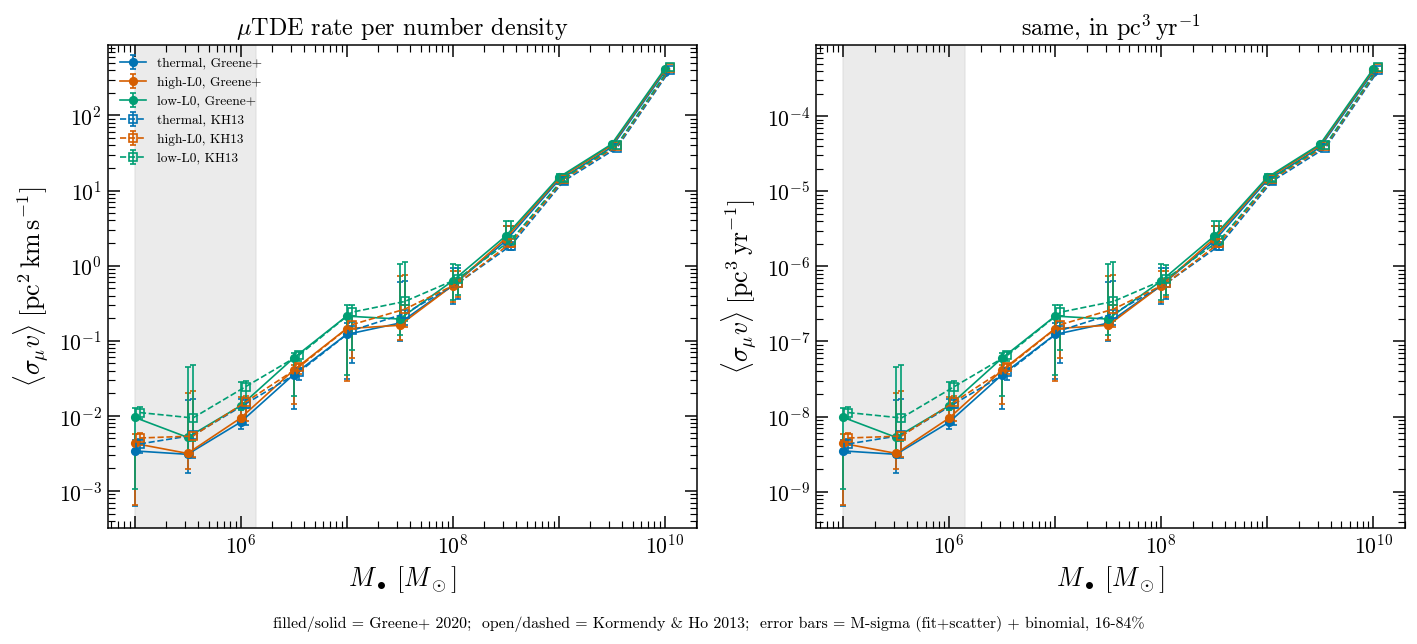

In [18]:
KMS_TO_PC_YR = 1.0227e-6       # 1 km/s = 1.0227e-6 pc/yr

def sigv_MC(M, reg, fit, nmc=4000, seed=1):
    """<sigma_mu v>(M) [pc^2 km/s] for a given p(a,e) and M-sigma fit:
       central value, binomial error, and the combined (M-sigma + binomial) 16-84 band."""
    p = MSIGMA[fit]; rng = np.random.default_rng(seed)
    al = rng.normal(p["alpha"], p["dalpha"], nmc)
    be = rng.normal(p["beta"],  p["dbeta"],  nmc)
    sc = rng.normal(0.0, p["eps"], nmc)
    vv = np.sqrt(3.0) * p["s0"] * 10**((np.log10(M) - al - sc)/be)
    draws = np.array([sigma_pop(M, v, reg, "grid")[0]*v for v in vv])
    draws = draws[np.isfinite(draws)]
    v0 = vinf_Msigma(M, fit); s0, ds0 = sigma_pop(M, v0, reg, "grid")
    cen, dbin = s0*v0, ds0*v0
    if draws.size == 0: return dict(cen=cen, dbin=dbin, med=np.nan, lo=np.nan, hi=np.nan)
    med = np.nanmedian(draws); lo, hi = np.nanpercentile(draws, [16, 84])
    lo = med - np.hypot(med-lo, dbin); hi = med + np.hypot(hi-med, dbin)   # fold in binomial
    return dict(cen=cen, dbin=dbin, med=med, lo=max(lo,0), hi=hi)

# ---- numbers: both relations, three regimes ----
print("<sigma_mu v>(M) [pc^2 km/s]  central [16-84 combined band]")
for fit in RELS:
    print(f"  --- {MSIGMA[fit]['label']} ---")
    for Mt in [1e5,1e6,1e7,1e8,1e9]:
        parts = []
        for reg in REGIMES:
            r = sigv_MC(Mt, reg, fit); parts.append(f"{REG_LBL[reg]}: {r['cen']:.2e} [{r['lo']:.2e},{r['hi']:.2e}]")
        print(f"    M={Mt:.0e}:  " + " | ".join(parts))

# ---- figure: overplot BOTH relations x THREE p(a,e), error bars = M-sigma propagated ----
fig, ax = plt.subplots(1, 2, figsize=(12.0, 5.2))
dx = {"greene": 1.0, "kh13": 10**0.05}     # small horizontal offset so the two relations' bars separate
for fit in RELS:
    st = REL_STYLE[fit]
    for reg in REGIMES:
        R = [sigv_MC(m, reg, fit) for m in Mtrack]
        med = np.array([r["med"] for r in R]); lo = np.array([r["lo"] for r in R]); hi = np.array([r["hi"] for r in R])
        good = np.isfinite(med)&(med>0)
        yerr = np.vstack([np.clip(med-lo,0,None), hi-med])[:,good]
        mfc = REG_COL[reg] if st["mfc"]=="full" else "none"
        lbl = f"{REG_LBL[reg]}, {('Greene+' if fit=='greene' else 'KH13')}"
        ax[0].errorbar(Mtrack[good]*dx[fit], med[good], yerr=yerr, fmt=st["marker"], ms=4.5, lw=1,
                       ls=st["ls"], capsize=2, color=REG_COL[reg], mfc=mfc, label=lbl)
        ax[1].errorbar(Mtrack[good]*dx[fit], (med*KMS_TO_PC_YR)[good], yerr=yerr*KMS_TO_PC_YR,
                       fmt=st["marker"], ms=4.5, lw=1, ls=st["ls"], capsize=2, color=REG_COL[reg], mfc=mfc)
for axk,lab in [(ax[0], r"$\langle\sigma_\mu v\rangle\;[{\rm pc}^2\,{\rm km\,s^{-1}}]$"),
                (ax[1], r"$\langle\sigma_\mu v\rangle\;[{\rm pc}^3\,{\rm yr^{-1}}]$")]:
    style_axes(axk, logx=True, logy=True); log_axis_dex(axk.xaxis)
    axk.set_xlabel(r"$M_\bullet\;[M_\odot]$"); axk.set_ylabel(lab)
    axk.axvspan(M_FLOOR, M_OBS_MIN, color="0.85", alpha=0.5, zorder=0)
ax[0].legend(frameon=False, fontsize=8.0, ncol=1, loc="upper left")
ax[0].set_title(r"$\mu$TDE rate per number density")
ax[1].set_title(r"same, in ${\rm pc}^3\,{\rm yr^{-1}}$")
fig.text(0.5, -0.02, "filled/solid = Greene+ 2020;  open/dashed = Kormendy & Ho 2013;  "
                     "error bars = M-sigma (fit+scatter) + binomial, 16-84%",
         ha="center", fontsize=9.5)
fig.tight_layout(); fig.savefig("sigmav_rate.png", bbox_inches="tight"); fig.savefig("sigmav_rate.pdf", bbox_inches="tight")
plt.show()

## 12. Emulator: grid interpolation of $\sigma_\mu$

A fast interpolator over the simulated grid (quadri-linear in $\log M_\bullet,\log a,e,\log v$).
Unlike the closed form of §7 it carries no functional assumption — it simply returns the Monte-Carlo
$\sigma_\mu$ between nodes, and `NaN` outside the grid.  Use the **formula** (§7) for extrapolation and
intuition; use the **emulator** for best-fidelity interpolation inside the grid.

In [19]:
from scipy.interpolate import RegularGridInterpolator
logM_ax, loga_ax, e_ax, logv_ax = np.log10(Mgrid), np.log10(agrid), egrid, np.log10(fgrid)
_SIG_fill = np.where(np.isfinite(SIG), SIG, 0.0)           # treat no-detection as 0 for interpolation
_emu = RegularGridInterpolator((logM_ax, loga_ax, e_ax, logv_ax), _SIG_fill,
                               bounds_error=False, fill_value=np.nan)
def sigma_emulator(M, a, e, frac, units="pc2"):
    pt = np.array([[np.log10(M), np.log10(a), e, np.log10(frac)]])
    s = float(np.asarray(_emu(pt)).ravel()[0])
    return s if units=="pc2" else s/AU2_TO_PC2

# emulator vs formula vs simulated at a few random in-grid nodes
rng = np.random.default_rng(0); idx = rng.choice(np.where(fhat>0)[0], 8, replace=False)
print(f"{'M':>9} {'a':>6} {'e':>4} {'v/vo':>6} {'sim':>10} {'emulator':>10} {'formula':>10}")
for k in idx:
    se = sigma_emulator(M[k],a[k],e[k],frac[k]); sf = sigma_formula(M[k],a[k],e[k],frac[k])
    print(f"{M[k]:9.1e} {a[k]:6g} {e[k]:4g} {frac[k]:6g} {sig_pc2[k]:10.2e} {se:10.2e} {sf:10.2e}")

        M      a    e   v/vo        sim   emulator    formula
  3.2e+08     20 0.95    0.1   3.87e+03   3.87e+03   2.74e+03
  3.2e+01      2  0.8  0.001   2.17e-04   2.17e-04   1.99e-04
  1.0e+01    0.3  0.4    0.1   1.68e-10   1.68e-10   1.42e-10
  3.2e+05     30  0.5     10   1.20e-05   1.20e-05   7.96e-06
  1.0e+04    0.2  0.8  0.001   2.47e-02   2.47e-02   3.50e-02
  3.2e+03      1  0.9  0.001   8.25e-02   8.25e-02   8.79e-02
  1.0e+01     20  0.6  0.001   1.46e-03   1.46e-03   9.42e-04
  1.0e+07    0.1  0.3     10   3.02e-07   3.02e-07   1.93e-07


## 13. Convergence & caveats

**Convergence.**  With $N\simeq1500$ draws per cell and $b^2$-uniform sampling, the per-cell estimator
is binomial; the error map (§5) is $\delta\sigma/\sigma=\sqrt{(1-\hat f)/(N\hat f)}$.  The histogram
below shows the distribution of relative errors over all detected cells.

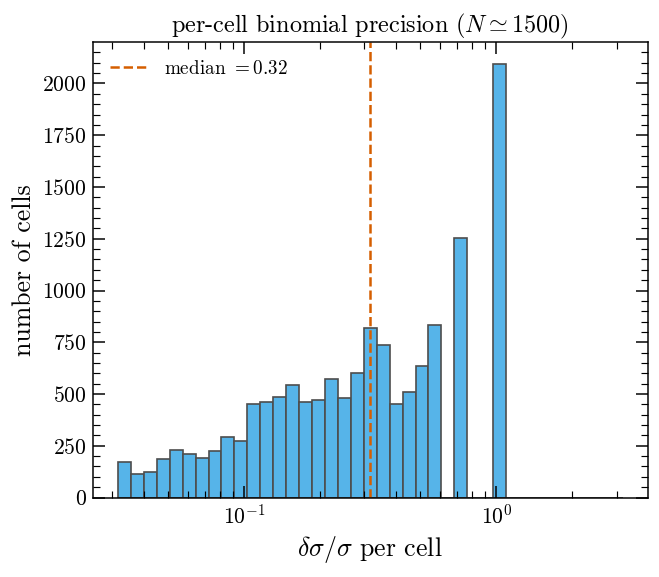

In [20]:
fig, ax = plt.subplots(figsize=(6.4, 5.0))
with np.errstate(divide="ignore", invalid="ignore"):
    rel_all = (dsig_pc2/sig_pc2)[fhat>0]
ax.hist(rel_all[np.isfinite(rel_all)], bins=np.logspace(-1.5,0.5,40), color=OI["skyblue"], edgecolor="0.3")
style_axes(ax, logx=True); ax.set_xlabel(r"$\delta\sigma/\sigma$ per cell"); ax.set_ylabel("number of cells")
ax.set_title(r"per-cell binomial precision ($N\simeq1500$)")
med = np.nanmedian(rel_all[np.isfinite(rel_all)])
ax.axvline(med, color=OI["vermillion"], ls="--", lw=1.5, label=fr"median $={med:.2f}$")
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("convergence.png", bbox_inches="tight"); fig.savefig("convergence.pdf", bbox_inches="tight")
plt.show()

**Caveats.**
- **Statistics vs sampling.** Numbers here use flat per-cell counting, correct *only* because the run
  is genuinely $b^2$-uniform.  Any subsample must preserve (or reweight to) that measure.
- **No-detection cells.** Grey heatmap cells are upper limits $\sigma<\pi b_{\max}^2/N$, not true zeros;
  the emulator treats them as 0 and will slightly under-interpolate there.
- **Semi-analytic form.** $f_\mu(\rho,e)$ is accurate to median $0.10$ dex but is a *fit*; near the
  born-disrupted edge ($\rho\to1$) and at $M_\bullet\gtrsim10^{10}\,M_\odot$ (plunge-dominated) it
  degrades.  $M_\bullet,v_\infty$ cancel in $f_\mu$ but fully control $\sigma$ via $b_{\max}^2$.
- **$v_\infty$ mapping.** The population average samples the nearest velocity node at each $a$; for
  very hard or very soft targets off the 7-node grid this is a nearest-node approximation.
- **$M_\bullet$–$\sigma$ relation (\S10$-$11).** Kormendy & Ho (2013) is used as a placeholder and is
  **extrapolated below $M_\bullet\sim10^6\,M_\odot$** (shaded region) where it is not calibrated; swap
  in the Greene+ IMBH-extended fit via `sigma_Msigma`.  The $\sim0.3$-dex intrinsic scatter of the
  relation is a systematic *not* included in the plotted error bars (which are binomial only).
- **Not computed here (needs a richer reduction).** Branching ratios for the other channels and the
  full $f_\mu(e,\beta)$ surface require per-outcome counts and the $\beta$-resolved histogram, which
  are not in the per-cell summary used by this notebook.

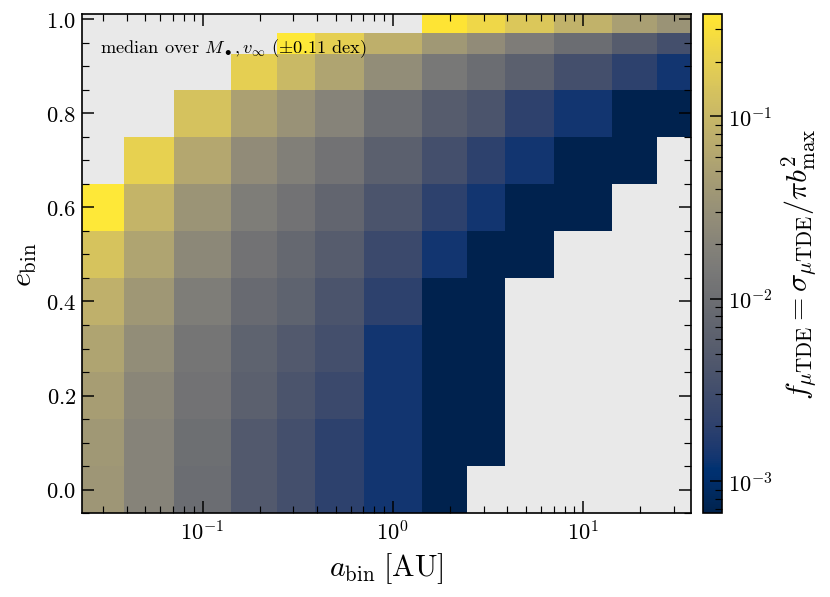

In [21]:
# ============ FIGURE: f_muTDE(a_bin,e_bin) heatmap (median over M_bullet, v_inf) ============
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
X_SYS_FMU=0.11                 # from the f_muTDE X-map (median over resolved cells)
def edges_log(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def edges_lin(c):
    c=np.asarray(c,float); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return ee

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
fmu=Nmu/Nt
ag,eg=np.unique(a),np.unique(e)
Z=np.full((len(eg),len(ag)),np.nan)
for i,ev in enumerate(eg):
    for j,av in enumerate(ag):
        m=np.isclose(a,av)&np.isclose(e,ev)&(Nt>0)
        if m.sum()>=5:
            med=np.median(fmu[m])
            if med>0: Z[i,j]=med
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges_log(ag),edges_lin(eg),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")
ax.set_xscale("log")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,rf"median over $M_\bullet,v_\infty$ ($\pm{X_SYS_FMU:.2f}$ dex)",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$f_{\mu\rm TDE}=\sigma_{\mu\rm TDE}/\pi b_{\rm max}^2$")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("fmu_heatmap.png",bbox_inches="tight"); fig.savefig("fmu_heatmap.pdf",bbox_inches="tight")
plt.show()

In [22]:
# === Random-forest feature importance for f_mu drivers (Breiman 2001) ===
# proves a_bin,e_bin dominate while M_bullet,v_inf do not matter.
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
fmu=np.maximum(Nmu,0.5)/Nt                         # 0.5-count floor so log is defined for N_mu=0 cells
ok=(Nt>0)&np.isfinite(frac)&(frac>0)
X=np.column_stack([np.log10(M[ok]),np.log10(a[ok]),e[ok],np.log10(frac[ok])])
y=np.log10(fmu[ok]); w=Nt[ok]
names=[r"log M_bullet", r"log a_bin", r"e_bin", r"log(v_inf/v_orb)"]

Xtr,Xte,ytr,yte,wtr,wte=train_test_split(X,y,w,test_size=0.3,random_state=0)
rf=RandomForestRegressor(n_estimators=400,min_samples_leaf=5,n_jobs=-1,random_state=0)
rf.fit(Xtr,ytr,sample_weight=wtr)
R2=rf.score(Xte,yte,sample_weight=wte); mdi=rf.feature_importances_
pi=permutation_importance(rf,Xte,yte,sample_weight=wte,n_repeats=30,random_state=0,n_jobs=-1)

order=np.argsort(pi.importances_mean)[::-1]
print(f"RandomForest for f_mu  (N_cells={ok.sum()},  test R^2={R2:.3f})")
print(f"{'parameter':>18} {'impurity':>10} {'perm.importance':>18}")
for i in order:
    print(f"{names[i]:>18} {mdi[i]:>10.3f}   {pi.importances_mean[i]:>8.3f} +/- {pi.importances_std[i]:.3f}")
tot=pi.importances_mean/pi.importances_mean.sum()
print("  perm. importance normalised:  "+",  ".join(f"{names[i].split()[-1]}={tot[i]*100:.0f}%" for i in order))

RandomForest for f_mu  (N_cells=18487,  test R^2=0.946)
         parameter   impurity    perm.importance
         log a_bin      0.452      1.272 +/- 0.019
             e_bin      0.420      0.980 +/- 0.016
      log M_bullet      0.086      0.188 +/- 0.007
  log(v_inf/v_orb)      0.042      0.100 +/- 0.004
  perm. importance normalised:  a_bin=50%,  e_bin=39%,  M_bullet=7%,  log(v_inf/v_orb)=4%


In [23]:
# Cite for feature importance algorithm:
# Breiman, L. (2001), “Random Forests,” Machine Learning 45(1), 5–32. doi:10.1023/A:1010933404324
# Pedregosa et al. (2011), “Scikit-learn: Machine Learning in Python,” JMLR 12, 2825–2830.

X(a,e): cells=68, median=0.118, 90th=0.300, max=0.466 dex


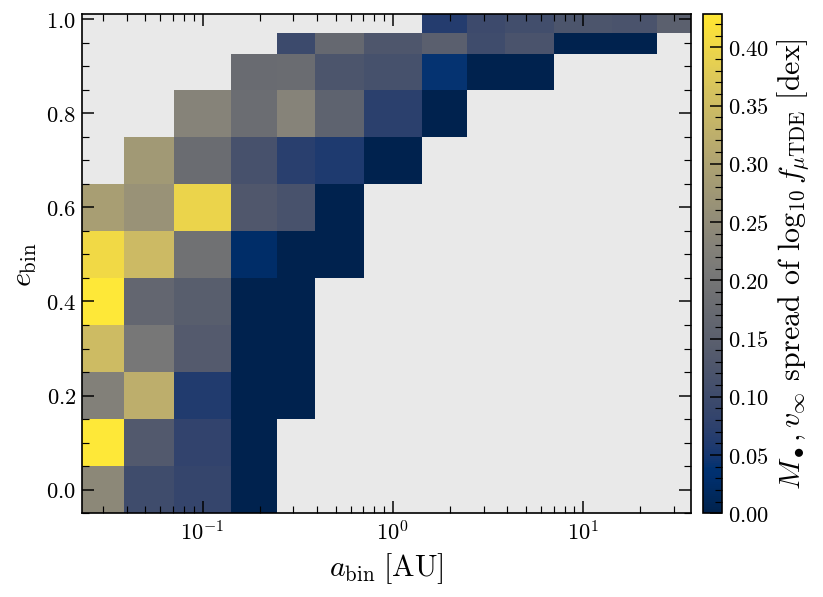

In [24]:
# ============ FIGURE: X(a,e) = M_bullet,v_inf spread of log10 f_muTDE (appendix) ============
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
MIN_SUB=20          # (M,v) sub-cells required per (a,e) cell
MIN_NMU=10          # min mu-TDEs per sub-cell so f_muTDE is resolved (not single-count quantised)
def edges_log(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def edges_lin(c):
    c=np.asarray(c,float); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return ee

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
ag,eg=np.unique(a),np.unique(e); LN10=np.log(10.0)
XZ=np.full((len(eg),len(ag)),np.nan)
for i,ev in enumerate(eg):
    for j,av in enumerate(ag):
        m=np.isclose(a,av)&np.isclose(e,ev)&(Nt>0)&(Nmu>=MIN_NMU)   # resolved sub-cells only
        if m.sum()>=MIN_SUB:
            f=Nmu[m]/Nt[m]; lf=np.log10(f)
            se=(1.0/LN10)*np.sqrt((1.0-f)/(f*Nt[m]))                # binomial error of log10 f
            raw=np.percentile(lf,84)-np.percentile(lf,16)
            nf=1.989*np.sqrt(np.mean(se**2))                        # 16-84 width of the sampling noise
            XZ[i,j]=np.sqrt(max(raw**2-nf**2,0.0))
finite=XZ[np.isfinite(XZ)]
print(f"X(a,e): cells={finite.size}, median={np.median(finite):.3f}, 90th={np.percentile(finite,90):.3f}, max={finite.max():.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges_log(ag),edges_lin(eg),np.ma.masked_invalid(XZ),cmap=CIV,shading="flat",
                 vmin=0,vmax=np.nanpercentile(XZ,98))
ax.set_xscale("log")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$M_\bullet,v_\infty$ spread of $\log_{10} f_{\mu\rm TDE}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
fig.savefig("fmu_Xmap.png",bbox_inches="tight"); fig.savefig("fmu_Xmap.pdf",bbox_inches="tight")
plt.show()

f_muTDE  median over cells:  raw=0.200  noise=0.150  corrected X=0.118 dex


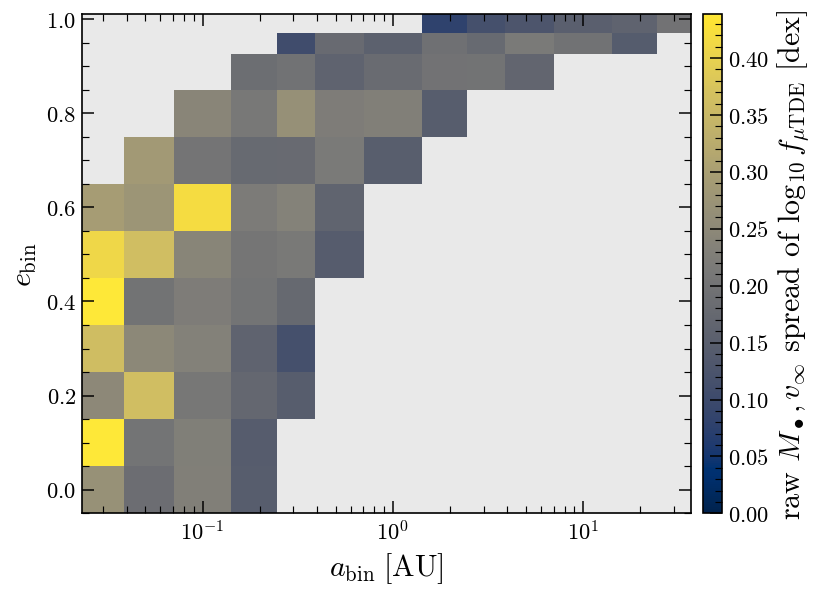

In [25]:
# ============ FIGURE: RAW X(a,e) = M,v spread of log10 f_muTDE (noise INCLUDED, not subtracted) ============
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
MIN_SUB=20; MIN_NMU=10
def edges_log(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def edges_lin(c):
    c=np.asarray(c,float); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return ee

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
ag,eg=np.unique(a),np.unique(e); LN10=np.log(10.0)
RAW=np.full((len(eg),len(ag)),np.nan); raw_all=[]; nf_all=[]; cor_all=[]
for i,ev in enumerate(eg):
    for j,av in enumerate(ag):
        m=np.isclose(a,av)&np.isclose(e,ev)&(Nt>0)&(Nmu>=MIN_NMU)
        if m.sum()>=MIN_SUB:
            f=Nmu[m]/Nt[m]; lf=np.log10(f)
            se=(1.0/LN10)*np.sqrt((1.0-f)/(f*Nt[m]))
            raw=np.percentile(lf,84)-np.percentile(lf,16)
            nf=1.989*np.sqrt(np.mean(se**2))
            RAW[i,j]=raw                                   # <-- RAW (noise included)
            raw_all.append(raw); nf_all.append(nf); cor_all.append(np.sqrt(max(raw**2-nf**2,0.0)))
print(f"f_muTDE  median over cells:  raw={np.median(raw_all):.3f}  noise={np.median(nf_all):.3f}  corrected X={np.median(cor_all):.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges_log(ag),edges_lin(eg),np.ma.masked_invalid(RAW),cmap=CIV,shading="flat",
                 vmin=0,vmax=np.nanpercentile(RAW,98))
ax.set_xscale("log")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"raw $M_\bullet,v_\infty$ spread of $\log_{10} f_{\mu\rm TDE}$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
fig.savefig("fmu_Xmap_raw.png",bbox_inches="tight"); fig.savefig("fmu_Xmap_raw.pdf",bbox_inches="tight")
plt.show()

f_muTDE formula residual: median=0.103, 90th=0.203 dex


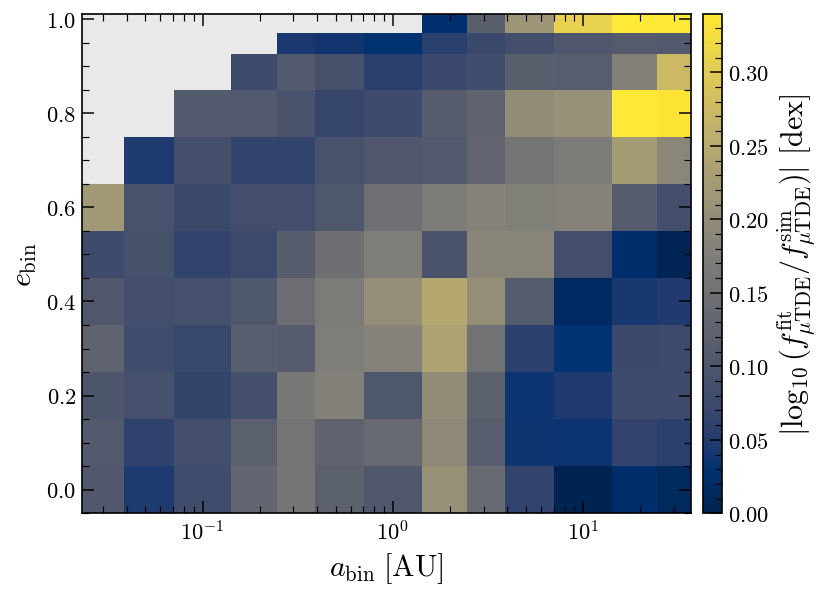

In [26]:
# ============ FIGURE: f_muTDE formula accuracy |log10(f_formula/f_sim)| on the (a,e) plane ============
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")
# --- validated semi-analytic f_muTDE (beta_crit law) ---
V1=29.7847; C_KMS=299792.458; m_bin=11.0
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1.0/3.0)
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)
def edges_log(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def edges_lin(c):
    c=np.asarray(c,float); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return ee

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
fsim=Nmu/Nt; ffit=fmu_formula(M,a,e,frac)
ok=(Nt>0)&(Nmu>0)&(ffit>0)&np.isfinite(frac)&(frac>0)
dex=np.full_like(fsim,np.nan); dex[ok]=np.abs(np.log10(ffit[ok]/fsim[ok]))   # per-cell |dex| residual
ag,eg=np.unique(a),np.unique(e)
Z=np.full((len(eg),len(ag)),np.nan)
for i,ev in enumerate(eg):
    for j,av in enumerate(ag):
        m=ok&np.isclose(a,av)&np.isclose(e,ev)
        if m.sum()>=5: Z[i,j]=np.median(dex[m])   # median |dex| over M_bullet,v_inf
print(f"f_muTDE formula residual: median={np.nanmedian(Z):.3f}, 90th={np.nanpercentile(Z,90):.3f} dex")

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges_log(ag),edges_lin(eg),np.ma.masked_invalid(Z),cmap=CIV,shading="flat",
                 vmin=0,vmax=np.nanpercentile(Z,98))
ax.set_xscale("log")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$|\log_{10}(f_{\mu\rm TDE}^{\rm fit}/f_{\mu\rm TDE}^{\rm sim})|$ [dex]")
cb.ax.tick_params(which="both",color="black",direction="in"); cb.ax.yaxis.set_minor_locator(AutoMinorLocator())
fig.savefig("fmu_residual.png",bbox_inches="tight"); fig.savefig("fmu_residual.pdf",bbox_inches="tight")
plt.show()

SEMIANALYTIC_fmu_heatmap OK


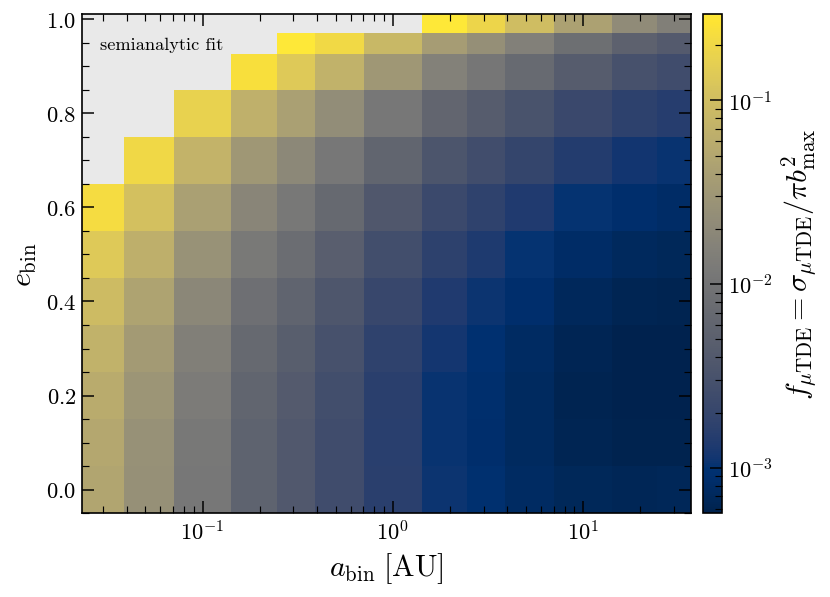

In [27]:
# ===== FIGURE: f_muTDE(a_bin,e_bin) heatmap -- SEMI-ANALYTIC FORMULA (not sim median) =====
# Same grid/marginalization as the simulation figure (median over the M_bullet, v_inf
# samples that exist in each (a,e) cell), but each cell is coloured by the semi-analytic
# law f_muTDE(M,a,e,v) evaluated at those samples instead of the measured fraction.
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")

# ---- semi-analytic f_muTDE law (M- and v-independent to ~0.1 dex) ----
V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)

def edges_log(c):
    c=np.log10(np.asarray(c,float)); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return 10**ee
def edges_lin(c):
    c=np.asarray(c,float); ee=np.empty(c.size+1)
    ee[1:-1]=0.5*(c[:-1]+c[1:]); ee[0]=c[0]-(c[1]-c[0])/2; ee[-1]=c[-1]+(c[-1]-c[-2])/2
    return ee

# reuse the per-cell arrays built from the bundle in the load cell above (no CSV)
fr=frac
ag,eg=np.unique(a),np.unique(e)
Z=np.full((len(eg),len(ag)),np.nan)
for i,ev in enumerate(eg):
    for j,av in enumerate(ag):
        m=np.isclose(a,av)&np.isclose(e,ev)&(Nt>0)       # same populated cells as the sim
        if m.sum()>=5:
            val=fmu_formula(M[m],av,ev,fr[m])            # law at each (M,v) sample in the cell
            val=val[val>0]
            if val.size: Z[i,j]=np.median(val)           # median over M_bullet, v_inf
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(edges_log(ag),edges_lin(eg),np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="flat")
ax.set_xscale("log")
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$f_{\mu\rm TDE}=\sigma_{\mu\rm TDE}/\pi b_{\rm max}^2$")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("fmu_heatmap_fit.png",bbox_inches="tight"); fig.savefig("fmu_heatmap_fit.pdf",bbox_inches="tight")
print("SEMIANALYTIC_fmu_heatmap OK")

SMOOTH_fmu_heatmap OK


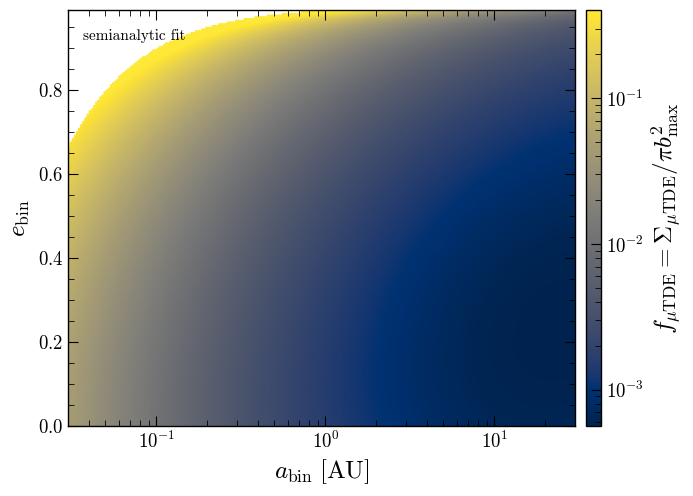

In [1]:
# ===== FIGURE: f_muTDE(a_bin,e_bin) SMOOTH semi-analytic heatmap (fine grid) =====
# Pure semi-analytic law on a fine (a,e) grid, marginalised over M_bullet and v_inf
# (median of the law over a log-grid of M and of frac=v_inf/v_orb), same as the
# binned semi-analytic figure but continuous. Masked where a(1-e) <= r_TDE (periapse
# inside the stellar TDE radius -> no micro-TDE).
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, AutoMinorLocator
CIV=mpl.colormaps["cividis"].copy(); CIV.set_bad("#e9e9e9")

# ---- semi-analytic f_muTDE law ----
V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)

# ---- fine plotted grid + marginalisation grids (match the sim ranges) ----
NA,NE=240,240
AF=np.logspace(np.log10(0.03),np.log10(30.0),NA)     # a_bin [AU]
EF=np.linspace(0.0,0.99,NE)                          # e_bin
Mm=np.logspace(1,10,13); Fm=np.logspace(-3,1,13)     # marginalise M_bullet, v_inf
MM,FF=np.meshgrid(Mm,Fm); Mr,Fr=MM.ravel(),FF.ravel()

Z=np.full((NE,NA),np.nan)
for i,ev in enumerate(EF):
    for j,av in enumerate(AF):
        if av*(1-ev)<=r_TDE: continue                # unphysical (periapse < r_TDE)
        val=fmu_formula(Mr,av,ev,Fr)                 # law over the M,v grid
        val=val[val>0]
        if val.size: Z[i,j]=np.median(val)           # median over M_bullet, v_inf
vmin,vmax=np.nanpercentile(Z,1),np.nanpercentile(Z,99)
norm=mpl.colors.LogNorm(vmin=vmin,vmax=vmax)

plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
fig,ax=plt.subplots(figsize=(7.0,5.4))
im=ax.pcolormesh(AF,EF,np.ma.masked_invalid(Z),cmap=CIV,norm=norm,shading="gouraud")
ax.set_xscale("log"); ax.set_xlim(AF[0],AF[-1]); ax.set_ylim(EF[0],EF[-1])
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(AutoMinorLocator())
ax.tick_params(which="both",direction="in",top=True,right=True,color="black")
ax.set_xlabel(r"$a_{\rm bin}\;[{\rm AU}]$"); ax.set_ylabel(r"$e_{\rm bin}$"); ax.set_box_aspect(0.82)
ax.text(0.03,0.955,r"semianalytic fit",transform=ax.transAxes,ha="left",va="top",fontsize=11,color="black")
fig.canvas.draw(); pos=ax.get_position()
cax=fig.add_axes([pos.x1+0.015,pos.y0,0.022,pos.height])
cb=fig.colorbar(im,cax=cax); cb.set_label(r"$f_{\mu\rm TDE}=\Sigma_{\mu\rm TDE}/\pi b_{\rm max}^2$")
cb.ax.tick_params(which="both",color="black",direction="in")
fig.savefig("fmu_heatmap_smooth.png",bbox_inches="tight"); fig.savefig("fmu_heatmap_smooth.pdf",bbox_inches="tight")
print("SMOOTH_fmu_heatmap OK")

# Rates:
---

HARD=False: k=1.112 [1.102,1.123]  Gamma_0@1e6=2.10e-06 (+/-0.12 dex)


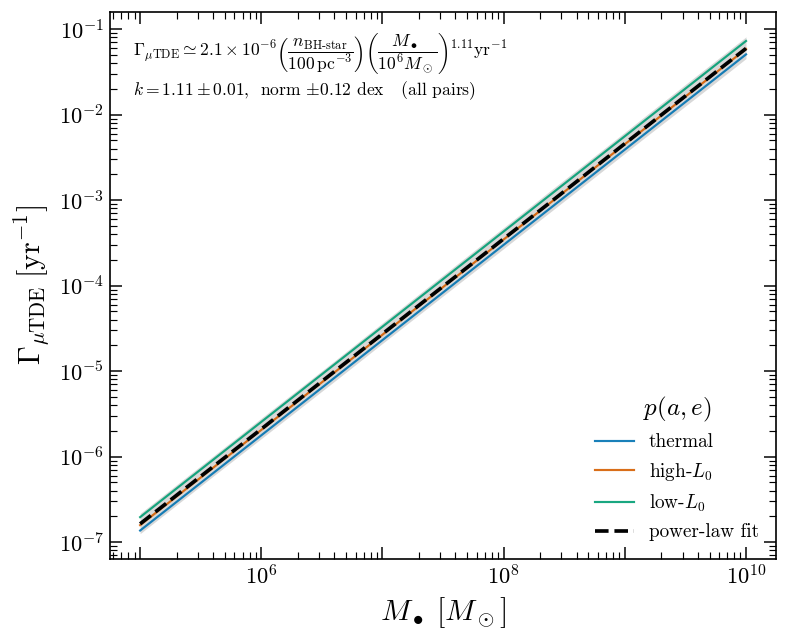

In [29]:
# ============ Gamma_muTDE(M): power-law fit; HARD toggle for hard-only BH-star pairs ============
import numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
trapz = np.trapezoid if hasattr(np,"trapezoid") else np.trapz
HARD = False      # <-- False: all pairs ; True: hard pairs only  [a < G m_BH / v_inf^2]

V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
AU2_TO_PC2=1.0/4.2545e10; KMS_TO_PC_YR=1.0227e-6
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)
def p_a(a,reg): return a**(2.0 if reg=="highL0" else 1.5)
def p_e(e,reg):
    if reg=="thermal": return 2.0*e
    if reg=="highL0":  return 1.2*e*(1.0+e)
    return e*(1.0+e)/np.sqrt(np.clip(1.0-e**2,1e-6,None))
REGIMES=["thermal","highL0","lowL0"]; REG_LBL={"thermal":"thermal","highL0":r"high-$L_0$","lowL0":r"low-$L_0$"}
OI=dict(blue="#0072B2",vermillion="#D55E00",green="#009E73"); REG_COL={"thermal":OI["blue"],"highL0":OI["vermillion"],"lowL0":OI["green"]}
A_GRID=np.logspace(np.log10(0.0101),np.log10(30.0),50); E_GRID=np.linspace(0,0.99,40)
def sigma_pop_formula(M,v_inf,reg):
    a_hard=m_BH*(V1/v_inf)**2                       # G m_BH / v_inf^2 [AU]  (hard-pair limit)
    num=den=0.0
    for aa in A_GRID:
        if HARD and aa>a_hard: continue             # keep only hard BH-star pairs
        frac=v_inf/(V1*np.sqrt(m_bin/aa)); emax=min(1-r_TDE/aa,0.99)
        if emax<=0: continue
        ev=E_GRID[E_GRID<emax]
        if ev.size<2: continue
        s=fmu_formula(M,aa,ev,frac)*np.pi*cell_scales(M,aa,frac)[3]*AU2_TO_PC2
        w=p_a(aa,reg)*p_e(ev,reg); num+=trapz(w*s,ev); den+=trapz(w*np.ones_like(ev),ev)
    return num/den if den>0 else np.nan
GR=dict(alpha=7.87,beta=4.55,eps=0.55,dalpha=0.06,dbeta=0.23,s0=160.0)
def vinf_of(M,al,be,sc): return np.sqrt(3.0)*GR["s0"]*10**((np.log10(M)-al-sc)/be)
N_BHSTAR=100.0; SIG_FMU_DEX=0.10; MREF=1e6
Mfit=np.logspace(5,10,11); lMr=np.log10(Mfit)-np.log10(MREF)
nmc=500; rng=np.random.default_rng(0); ks=[]; c0s=[]
for _ in range(nmc):
    al=rng.normal(GR["alpha"],GR["dalpha"]); be=rng.normal(GR["beta"],GR["dbeta"])
    fm=10**rng.normal(0,SIG_FMU_DEX); reg=REGIMES[rng.integers(3)]
    G=np.array([N_BHSTAR*sigma_pop_formula(M,vinf_of(M,al,be,0.0),reg)*vinf_of(M,al,be,0.0)*KMS_TO_PC_YR*fm for M in Mfit])
    g=np.isfinite(G)&(G>0); A=np.column_stack([np.ones(g.sum()),lMr[g]])
    c,k=np.linalg.lstsq(A,np.log10(G[g]),rcond=None)[0]; c0s.append(c); ks.append(k)
ks=np.array(ks); c0s=np.array(c0s); G0=10**c0s
kmed=np.median(ks); G0med=np.median(G0); ndex=0.5*(np.percentile(np.log10(G0),84)-np.percentile(np.log10(G0),16))
print(f"HARD={HARD}: k={kmed:.3f} [{np.percentile(ks,16):.3f},{np.percentile(ks,84):.3f}]  Gamma_0@1e6={G0med:.2e} (+/-{ndex:.2f} dex)")
plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,"legend.fontsize":11.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
def _ev(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""
Mtr=np.logspace(5,10,26); lMrp=np.log10(Mtr)-np.log10(MREF)
fig,ax=plt.subplots(figsize=(7.4,5.6))
for reg in REGIMES:
    G=np.array([N_BHSTAR*sigma_pop_formula(M,vinf_of(M,GR["alpha"],GR["beta"],0.0),reg)*vinf_of(M,GR["alpha"],GR["beta"],0.0)*KMS_TO_PC_YR for M in Mtr])
    ax.plot(Mtr,G,"-",color=REG_COL[reg],lw=1.3,alpha=0.9,label=REG_LBL[reg])
draws=10**(c0s[:,None]+ks[:,None]*lMrp[None,:])
ax.fill_between(Mtr,np.percentile(draws,16,0),np.percentile(draws,84,0),color="0.5",alpha=0.30,lw=0)
ax.plot(Mtr,np.median(draws,0),"k--",lw=2.2,label="power-law fit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_ev))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$\Gamma_{\mu\rm TDE}\;[{\rm yr^{-1}}]$"); ax.set_box_aspect(0.82)
g0e=int(np.floor(np.log10(G0med))); g0m=G0med/10**g0e
ax.text(0.035,0.965,
    rf"$\Gamma_{{\mu\rm TDE}}\simeq {g0m:.1f}\times10^{{{g0e}}}\left(\dfrac{{n_{{\rm BH\text{{-}}star}}}}{{100\,{{\rm pc^{{-3}}}}}}\right)\left(\dfrac{{M_\bullet}}{{10^{6}M_\odot}}\right)^{{{kmed:.2f}}}{{\rm yr^{{-1}}}}$"
    +"\n"+rf"$k={kmed:.2f}\pm{0.5*(np.percentile(ks,84)-np.percentile(ks,16)):.2f}$,  norm $\pm{ndex:.2f}$ dex"
    +("   (hard pairs)" if HARD else "   (all pairs)"),
    transform=ax.transAxes,ha="left",va="top",fontsize=10.5)
ax.legend(frameon=False,loc="lower right",title=r"$p(a,e)$")
fig.tight_layout()
fig.savefig(f"rate_gamma_fit_{'hard' if HARD else 'all'}.png",bbox_inches="tight")
fig.savefig(f"rate_gamma_fit_{'hard' if HARD else 'all'}.pdf",bbox_inches="tight")
plt.show()

HARD=True: k=0.916 [0.870,0.935]  Gamma_0@1e6=1.03e-06 (+/-0.15 dex)


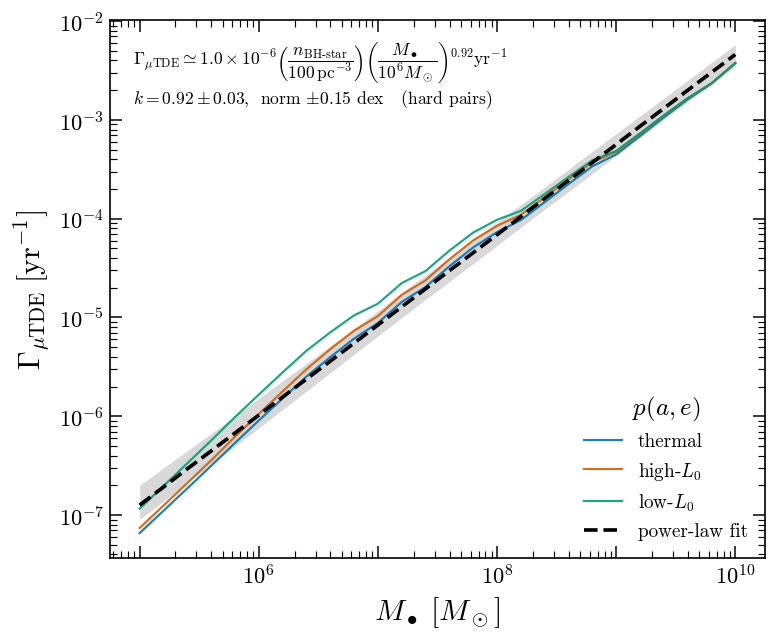

In [30]:
# ============ Gamma_muTDE(M): power-law fit; HARD toggle for hard-only BH-star pairs ============
import numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
trapz = np.trapezoid if hasattr(np,"trapezoid") else np.trapz
HARD = True      # <-- False: all pairs ; True: hard pairs only  [a < G m_BH / v_inf^2]

V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
AU2_TO_PC2=1.0/4.2545e10; KMS_TO_PC_YR=1.0227e-6
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)
def p_a(a,reg): return a**(2.0 if reg=="highL0" else 1.5)
def p_e(e,reg):
    if reg=="thermal": return 2.0*e
    if reg=="highL0":  return 1.2*e*(1.0+e)
    return e*(1.0+e)/np.sqrt(np.clip(1.0-e**2,1e-6,None))
REGIMES=["thermal","highL0","lowL0"]; REG_LBL={"thermal":"thermal","highL0":r"high-$L_0$","lowL0":r"low-$L_0$"}
OI=dict(blue="#0072B2",vermillion="#D55E00",green="#009E73"); REG_COL={"thermal":OI["blue"],"highL0":OI["vermillion"],"lowL0":OI["green"]}
A_GRID=np.logspace(np.log10(0.0101),np.log10(30.0),50); E_GRID=np.linspace(0,0.99,40)
def sigma_pop_formula(M,v_inf,reg):
    a_hard=m_BH*(V1/v_inf)**2                       # G m_BH / v_inf^2 [AU]  (hard-pair limit)
    num=den=0.0
    for aa in A_GRID:
        if HARD and aa>a_hard: continue             # keep only hard BH-star pairs
        frac=v_inf/(V1*np.sqrt(m_bin/aa)); emax=min(1-r_TDE/aa,0.99)
        if emax<=0: continue
        ev=E_GRID[E_GRID<emax]
        if ev.size<2: continue
        s=fmu_formula(M,aa,ev,frac)*np.pi*cell_scales(M,aa,frac)[3]*AU2_TO_PC2
        w=p_a(aa,reg)*p_e(ev,reg); num+=trapz(w*s,ev); den+=trapz(w*np.ones_like(ev),ev)
    return num/den if den>0 else np.nan
GR=dict(alpha=7.87,beta=4.55,eps=0.55,dalpha=0.06,dbeta=0.23,s0=160.0)
def vinf_of(M,al,be,sc): return np.sqrt(3.0)*GR["s0"]*10**((np.log10(M)-al-sc)/be)
N_BHSTAR=100.0; SIG_FMU_DEX=0.10; MREF=1e6
Mfit=np.logspace(5,10,11); lMr=np.log10(Mfit)-np.log10(MREF)
nmc=500; rng=np.random.default_rng(0); ks=[]; c0s=[]
for _ in range(nmc):
    al=rng.normal(GR["alpha"],GR["dalpha"]); be=rng.normal(GR["beta"],GR["dbeta"])
    fm=10**rng.normal(0,SIG_FMU_DEX); reg=REGIMES[rng.integers(3)]
    G=np.array([N_BHSTAR*sigma_pop_formula(M,vinf_of(M,al,be,0.0),reg)*vinf_of(M,al,be,0.0)*KMS_TO_PC_YR*fm for M in Mfit])
    g=np.isfinite(G)&(G>0); A=np.column_stack([np.ones(g.sum()),lMr[g]])
    c,k=np.linalg.lstsq(A,np.log10(G[g]),rcond=None)[0]; c0s.append(c); ks.append(k)
ks=np.array(ks); c0s=np.array(c0s); G0=10**c0s
kmed=np.median(ks); G0med=np.median(G0); ndex=0.5*(np.percentile(np.log10(G0),84)-np.percentile(np.log10(G0),16))
print(f"HARD={HARD}: k={kmed:.3f} [{np.percentile(ks,16):.3f},{np.percentile(ks,84):.3f}]  Gamma_0@1e6={G0med:.2e} (+/-{ndex:.2f} dex)")
plt.rcParams.update({"font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,"legend.fontsize":11.5,
    "axes.linewidth":1.0,"xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4})
def _ev(x,_):
    if x<=0: return ""
    p=int(round(np.log10(x))); return rf"$10^{{{p}}}$" if p%2==0 else ""
Mtr=np.logspace(5,10,26); lMrp=np.log10(Mtr)-np.log10(MREF)
fig,ax=plt.subplots(figsize=(7.4,5.6))
for reg in REGIMES:
    G=np.array([N_BHSTAR*sigma_pop_formula(M,vinf_of(M,GR["alpha"],GR["beta"],0.0),reg)*vinf_of(M,GR["alpha"],GR["beta"],0.0)*KMS_TO_PC_YR for M in Mtr])
    ax.plot(Mtr,G,"-",color=REG_COL[reg],lw=1.3,alpha=0.9,label=REG_LBL[reg])
draws=10**(c0s[:,None]+ks[:,None]*lMrp[None,:])
ax.fill_between(Mtr,np.percentile(draws,16,0),np.percentile(draws,84,0),color="0.5",alpha=0.30,lw=0)
ax.plot(Mtr,np.median(draws,0),"k--",lw=2.2,label="power-law fit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_locator(LogLocator(base=10,numticks=30)); ax.xaxis.set_major_formatter(plt.FuncFormatter(_ev))
ax.xaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10,subs=np.arange(2,10),numticks=100)); ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"$M_\bullet\;[M_\odot]$"); ax.set_ylabel(r"$\Gamma_{\mu\rm TDE}\;[{\rm yr^{-1}}]$"); ax.set_box_aspect(0.82)
g0e=int(np.floor(np.log10(G0med))); g0m=G0med/10**g0e
ax.text(0.035,0.965,
    rf"$\Gamma_{{\mu\rm TDE}}\simeq {g0m:.1f}\times10^{{{g0e}}}\left(\dfrac{{n_{{\rm BH\text{{-}}star}}}}{{100\,{{\rm pc^{{-3}}}}}}\right)\left(\dfrac{{M_\bullet}}{{10^{6}M_\odot}}\right)^{{{kmed:.2f}}}{{\rm yr^{{-1}}}}$"
    +"\n"+rf"$k={kmed:.2f}\pm{0.5*(np.percentile(ks,84)-np.percentile(ks,16)):.2f}$,  norm $\pm{ndex:.2f}$ dex"
    +("   (hard pairs)" if HARD else "   (all pairs)"),
    transform=ax.transAxes,ha="left",va="top",fontsize=10.5)
ax.legend(frameon=False,loc="lower right",title=r"$p(a,e)$")
fig.tight_layout()
fig.savefig(f"rate_gamma_fit_{'hard' if HARD else 'all'}.png",bbox_inches="tight")
fig.savefig(f"rate_gamma_fit_{'hard' if HARD else 'all'}.pdf",bbox_inches="tight")
plt.show()

In [31]:
import numpy as np
trapz = np.trapezoid if hasattr(np,"trapezoid") else np.trapz
N_BHSTAR=100.0; SIG_FMU_DEX=0.10
BHMF_logM=np.arange(5.0,10.01,0.25)
BHMF_NC=np.array([-2.83,-2.87,-2.90,-2.94,-2.96,-2.97,-2.98,-2.98,-2.99,-3.00,-3.03,-3.08,-3.14,-3.23,-3.34,-3.47,-3.64,-3.83,-4.04,-4.29,-4.58])
focc_pts={"early":(np.array([5.85,6.5,7.2,7.7,8.1,8.65,9.3,10.05,10.8,11.45]),
                   np.array([0.06,0.17,0.33,0.50,0.64,0.81,0.73,0.58,0.36,0.13])),
          "late": (np.array([5.85,6.5,7.2,8.0,8.5,9.4,10.05,10.8]),
                   np.array([0.23,0.17,0.30,0.71,0.65,0.79,0.63,0.67]))}
def focc(occ,lMs,doff=0.0): x,y=focc_pts[occ]; return np.clip(np.interp(lMs,x,y)+doff,0,1)
alM0,beM0,epsM,dalM,dbeM,M0=7.43,1.61,0.81,0.09,0.12,3e10          # Greene M_BH-M* (All,limits)
def focc_avg(occ,alM,beM,doff,gx,gw):
    if occ=="unity": return np.ones(len(BHMF_logM))
    lc=np.log10(M0)+(BHMF_logM-alM)/beM; sig=epsM/abs(beM)
    return np.sum(gw[None,:]*focc(occ,lc[:,None]+gx[None,:]*sig,doff),axis=1)
V1=29.7847; C_KMS=299792.458; m_BH=10.0; m_star=1.0; m_bin=m_BH+m_star
RSUN_AU=695700.0/1.495978707e8; r_TDE=1.0*RSUN_AU*(10.0/1.0)**(1/3)
AU2_TO_PC2=1.0/4.2545e10; KMS_TO_PC_YR=1.0227e-6
import json as _json, os as _os
_fit = _json.load(open('fmu_fit.json')) if _os.path.exists('fmu_fit.json') else {'CF': [-0.25779227,1.46935967,-0.21427309,0.17756551,-0.65974393]}
CF = np.array(_fit['CF'])   # f_mu fit: v2 values from fmu_fit.json (analyze_mutde_cross_sections); v1 fallback
def cell_scales(M,a,frac):
    m_tot=M+m_bin; r_t=a*(M/m_bin)**(1/3); v_inf=frac*V1*np.sqrt(m_bin/a)
    r_foc=2*V1*V1*m_tot/v_inf**2; r_g=(V1*V1/C_KMS**2)*m_tot
    rp_max=np.maximum(10*r_t,8*r_g); return r_t,r_foc,rp_max,rp_max**2+r_foc*rp_max
def fmu_formula(M,a,e,frac):
    r_t,r_foc,rp_max,b2=cell_scales(M,a,frac)
    Lr=np.log10(a*(1-e)/r_TDE); bc=10**(CF[0]+CF[1]*Lr+CF[2]*Lr**2+CF[3]*e+CF[4]*e**2)
    r_c=r_t/bc; return np.clip((r_c**2+r_foc*r_c)/b2,0,1)
def p_a(a,reg): return a**(2.0 if reg=="highL0" else 1.5)
def p_e(e,reg):
    if reg=="thermal": return 2.0*e
    if reg=="highL0":  return 1.2*e*(1.0+e)
    return e*(1.0+e)/np.sqrt(np.clip(1.0-e**2,1e-6,None))
REGIMES=["thermal","highL0","lowL0"]
A_GRID=np.logspace(np.log10(0.0101),np.log10(30.0),50); E_GRID=np.linspace(0,0.99,40)
def sigma_pop(M,v_inf,reg,hard):
    a_hard=m_BH*(V1/v_inf)**2; num=den=0.0
    for aa in A_GRID:
        if hard and aa>a_hard: continue
        frac=v_inf/(V1*np.sqrt(m_bin/aa)); emax=min(1-r_TDE/aa,0.99)
        if emax<=0: continue
        ev=E_GRID[E_GRID<emax]
        if ev.size<2: continue
        s=fmu_formula(M,aa,ev,frac)*np.pi*cell_scales(M,aa,frac)[3]*AU2_TO_PC2
        w=p_a(aa,reg)*p_e(ev,reg); num+=trapz(w*s,ev); den+=trapz(w*np.ones_like(ev),ev)
    return num/den if den>0 else np.nan
Mgrid=10**BHMF_logM; VGRID=np.logspace(-0.5,3.8,60); lVG=np.log10(VGRID)
SIGT={(r,h):np.array([[sigma_pop(M,v,r,h) for v in VGRID] for M in Mgrid]) for r in REGIMES for h in [False,True]}
LSIG={k:np.where(v>0,np.log10(np.clip(v,1e-300,None)),np.nan) for k,v in SIGT.items()}
def sig_vec(r,h,iM,v):
    y=LSIG[(r,h)][iM]; ok=np.isfinite(y)
    return 10**np.interp(np.log10(v),lVG[ok],y[ok],left=np.nan,right=np.nan) if ok.sum()>1 else np.full_like(v,np.nan)
AL0,BE0,EPS,DAL,DBE,S0=7.87,4.55,0.55,0.06,0.23,160.0             # M-sigma (All,limits)
gx,gw=np.polynomial.hermite_e.hermegauss(21); gw=gw/np.sqrt(2*np.pi)
def Gvec(r,h,al,be,fm):
    out=np.empty(len(Mgrid))
    for iM,lM in enumerate(BHMF_logM):
        v=np.sqrt(3.0)*S0*10**((lM-al-gx*EPS)/be)
        G=N_BHSTAR*sig_vec(r,h,iM,v)*v*KMS_TO_PC_YR*fm
        out[iM]=np.nansum(gw*np.where(np.isfinite(G),G,0.0))
    return out
dn=10**BHMF_NC
def gamma(Gv,fo): return trapz(Gv*dn*fo*1e9,BHMF_logM)
OCCS=["unity","early","late"]; HARDS=[False,True]
rng=np.random.default_rng(0); NMC=600
draws={(o,h):[] for o in OCCS for h in HARDS}
for _ in range(NMC):
    r=REGIMES[rng.integers(3)]                       # <-- p(a,e) regime drawn each MC -> folded into band
    al,be=rng.normal(AL0,DAL),rng.normal(BE0,DBE); fm=10**rng.normal(0,SIG_FMU_DEX)
    alM,beM=rng.normal(alM0,dalM),rng.normal(beM0,dbeM); doff=rng.normal(0,0.06)
    Gh={h:Gvec(r,h,al,be,fm) for h in HARDS}
    fo={o:focc_avg(o,alM,beM,doff,gx,gw) for o in OCCS}
    for o in OCCS:
        for h in HARDS: draws[(o,h)].append(gamma(Gh[h],fo[o]))
print(f"gamma_muTDE [Gpc^-3 yr^-1]  (N_BHSTAR={N_BHSTAR:g}, BHMF=NC; p(a,e) folded into band)")
print(f"{'occupation':>10} {'binary':>6} |  median   [16-84 band]")
ks=[]; md=[]; lo=[]; hi=[]
for o in OCCS:
    for h in HARDS:
        a=np.array(draws[(o,h)]); m,l,u=np.percentile(a,[50,16,84])
        ks.append(f"{o}|{'hard' if h else 'all'}"); md.append(m); lo.append(l); hi.append(u)
        print(f"{o:>10} {'hard' if h else 'all':>6} |  {m:6.0f}   [{l:5.0f}, {u:5.0f}]")
np.savez("gamma6.npz",keys=np.array(ks),med=np.array(md),lo=np.array(lo),hi=np.array(hi))

gamma_muTDE [Gpc^-3 yr^-1]  (N_BHSTAR=100, BHMF=NC; p(a,e) folded into band)
occupation binary |  median   [16-84 band]
     unity    all |    2226   [ 1686,  2898]
     unity   hard |     281   [  217,   360]
     early    all |     441   [  277,   671]
     early   hard |      67   [   45,    96]
      late    all |    1482   [ 1103,  1989]
      late   hard |     187   [  140,   248]


wrote horizon6.png/.pdf   (top-curve low-z slope: R propto z^3.02)


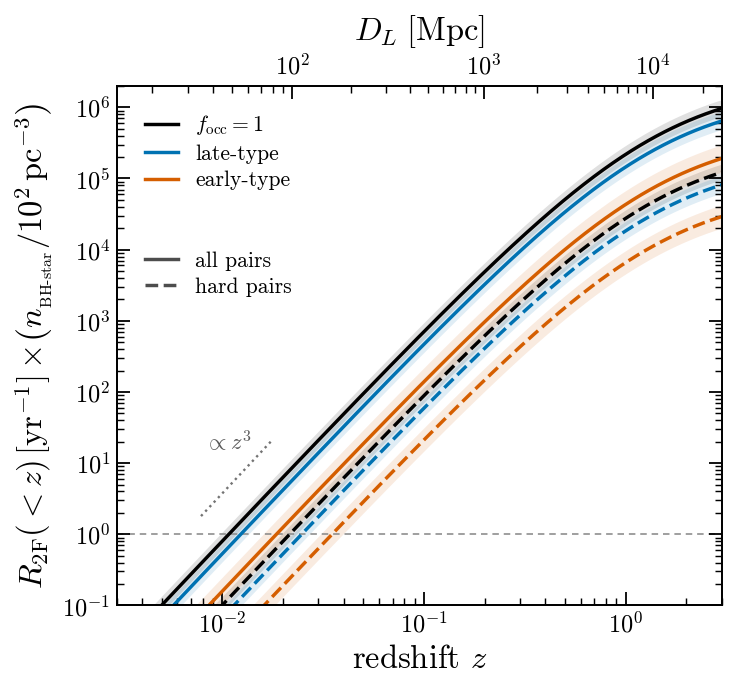

In [32]:
# ===== Observer-frame cumulative rate R_2F(<z): 6 cases, z & D_L axes =====
import numpy as np
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter, FixedLocator, FixedFormatter
from matplotlib.lines import Line2D
from astropy.cosmology import Planck18 as cosmo
import astropy.units as u

plt.rcParams.update({
    "figure.dpi":130,"savefig.dpi":220,
    "font.family":"serif","font.serif":["cmr10","DejaVu Serif"],
    "mathtext.fontset":"cm","axes.formatter.use_mathtext":True,"axes.unicode_minus":False,
    "font.size":15,"axes.labelsize":18,"xtick.labelsize":13.5,"ytick.labelsize":13.5,
    "legend.fontsize":12,"axes.linewidth":1.0,
    "xtick.direction":"in","ytick.direction":"in","xtick.top":True,"ytick.right":True,
    "xtick.minor.visible":True,"ytick.minor.visible":True,
    "xtick.major.size":7,"ytick.major.size":7,"xtick.minor.size":4,"ytick.minor.size":4,
    "xtick.major.width":1.0,"ytick.major.width":1.0,"xtick.minor.width":0.8,"ytick.minor.width":0.8,
})

# ---- load gamma6.npz : keys "occ|bin" -> (med, lo, hi) in Gpc^-3 yr^-1 ----
d = np.load("gamma6.npz", allow_pickle=True)
G = {tuple(k.split("|")): (d["med"][i], d["lo"][i], d["hi"][i])
     for i, k in enumerate(d["keys"])}

OCCS = ["unity", "late", "early"]          # color
BINS = ["all", "hard"]                      # linestyle
COL  = {"unity":"k", "late":"#0072B2", "early":"#D55E00"}   # Okabe-Ito, CB-safe
LS   = {"all":"-", "hard":"--"}

XMIN, ZMAX, YMIN, YMAX = 3e-3, 3.0, 1e-1, 2e6

# ---- cosmology: R(<z) = int_0^z [gamma/(1+z')] dV_c/dz' dz',  gamma const in V_c ----
z    = np.logspace(-3, np.log10(ZMAX), 600)        # integrate from low z; display from XMIN
dVdz = cosmo.differential_comoving_volume(z).to(u.Mpc**3/u.sr).value * 4*np.pi  # Mpc^3
DL   = cosmo.luminosity_distance(z).to(u.Mpc).value
def Rate(g):                                   # g in Gpc^-3 yr^-1 -> yr^-1
    integ = (g*1e-9)/(1+z) * dVdz
    return np.concatenate([[0.0], np.cumsum(0.5*(integ[1:]+integ[:-1])*np.diff(z))])

fig, ax = plt.subplots(figsize=(7.0,5.4))   # same figsize & box_aspect as the f_mu heatmap
for occ in OCCS:
    for b in BINS:
        med, lo, hi = G[(occ, b)]
        ax.fill_between(z, Rate(lo), Rate(hi), color=COL[occ], alpha=0.12, lw=0)
        ax.plot(z, Rate(med), color=COL[occ], ls=LS[b], lw=1.9)

# ---- low-z power-law fit of the top-most curve (unity / all) + guide line ----
Rtop = Rate(G[("unity","all")][0])
mfit = (z >= 2e-3) & (z <= 2e-2)
p    = np.polyfit(np.log10(z[mfit]), np.log10(Rtop[mfit]), 1)[0]
plbl = f"{p:.0f}" if abs(p-round(p)) < 0.1 else f"{p:.1f}"
z0, R0 = 1e-2, np.interp(1e-2, z, Rtop)
# guide line set by two rate endpoints, BOTH > 1 (never crosses the y=1 line),
# then shifted to smaller z so it sits parallel to and left of the top curve
yA = np.array([1.8, 20.0])
zA = 0.60 * z0 * (yA/R0)**(1.0/p)
ax.plot(zA, yA, ls=":", lw=1.3, color="0.45", zorder=5)
ax.annotate(rf"$\propto z^{{{plbl}}}$",            # label to the LEFT of the line
            (zA[1]*0.80, yA[1]), color="0.35", fontsize=12.5,
            ha="right", va="center")

# ---- axes ----
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(XMIN, ZMAX); ax.set_ylim(YMIN, YMAX)
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10), numticks=100))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2,10), numticks=100))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"redshift $z$")
ax.set_ylabel(r"$R_{\rm 2F}(<z)\,[{\rm yr^{-1}}]\times\!\left("
              r"n_{_{\rm BH\text{-}star}}/10^{2}\,{\rm pc^{-3}}\right)$")  # 18 pt (matches heatmap)
ax.set_box_aspect(0.82)

# 1 transient / yr reference line (text label removed per request)
ax.axhline(1.0, color="0.55", lw=0.9, ls=(0,(4,3)), zorder=1)

# ---- top axis: luminosity distance D_L(z) with explicit decade ticks ----
DL2z = lambda dl: np.interp(dl, DL, z)
secax = ax.twiny()
secax.set_xscale("log")
secax.set_xlim(ax.get_xlim())                   # share the z range
DLmin, DLmax = np.interp(XMIN, z, DL), DL.max()   # only label ticks inside the view
maj  = [v for v in [1,10,100,1e3,1e4] if DLmin <= v <= DLmax]
minr = [m*10.0**k for k in range(0,5) for m in range(2,10)]
minr = [v for v in minr if DLmin <= v <= DLmax]
secax.xaxis.set_major_locator(FixedLocator([DL2z(v) for v in maj]))
secax.xaxis.set_major_formatter(FixedFormatter(
    [rf"$10^{{{int(round(np.log10(v)))}}}$" for v in maj]))
secax.xaxis.set_minor_locator(FixedLocator([DL2z(v) for v in minr]))
secax.xaxis.set_minor_formatter(NullFormatter())
secax.tick_params(direction="in", which="both", top=True)
secax.set_xlabel(r"$D_L\;[{\rm Mpc}]$", fontsize=18, labelpad=8)

# ---- two naked legends (color key + linestyle key), upper-left ----
col_h = [Line2D([],[],color=COL["unity"],lw=1.9),
         Line2D([],[],color=COL["late"], lw=1.9),
         Line2D([],[],color=COL["early"],lw=1.9)]
col_l = [r"$f_{\rm occ}=1$", "late-type", "early-type"]
ls_h  = [Line2D([],[],color="0.3",lw=1.9,ls="-"),
         Line2D([],[],color="0.3",lw=1.9,ls="--")]
ls_l  = ["all pairs", "hard pairs"]

leg1 = ax.legend(col_h, col_l, frameon=False, loc="upper left",
                 bbox_to_anchor=(0.015,0.985), handlelength=1.5, labelspacing=0.32)
ax.add_artist(leg1)
ax.legend(ls_h, ls_l, frameon=False, loc="upper left",
          bbox_to_anchor=(0.015,0.72), handlelength=1.5, labelspacing=0.32)

# explicit margins; left is wide enough that the tall y-label is never clipped
fig.subplots_adjust(left=0.30, right=0.965, top=0.86, bottom=0.12)
fig.savefig("horizon6.png", bbox_inches="tight")
fig.savefig("horizon6.pdf", bbox_inches="tight")
print(f"wrote horizon6.png/.pdf   (top-curve low-z slope: R propto z^{p:.2f})")

# Convergence tests:

In [33]:
# section 13 convergence checks read the full bundle into a DataFrame
import pandas as pd, h5py, os
_bundle = os.environ.get("SMBH_BUNDLE", "../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5")
with h5py.File(_bundle, "r") as _f:
    _R = _f["results"]
    _want = ["M_smbh","a_bin","e_bin","beta","v_inf","outcome","incl"]
    df = pd.DataFrame({c: (_R[c].asstr()[:] if c=="outcome" else _R[c][:])
                       for c in _want if c in _R})
print(f"loaded {len(df):,} rows from {_bundle}")

print(df["outcome"].value_counts())
print("\nunique values per parameter:")
for c in [c for c in ["M_smbh","a_bin","e_bin","beta","v_inf","incl"] if c in df.columns]:
    u = sorted(df[c].unique())
    print(f"  {c}: {df[c].nunique()} values -> {u[:8]}{' ...' if len(u) > 8 else ''}")

loaded 27,633,319 rows from ../../../data/bhstar/campaign2_rp10/smbh_bhstar_bundle.h5
outcome
FLYBY                     22224906
EXCHANGE_star2             1267040
EXCHANGE_bh1               1225718
BOUND_TRIPLE                934514
TDE:star2_by_bh1            788113
PLUNGE:bh1_into_SMBH        597662
IONIZATION                  326029
PLUNGE:star2_into_SMBH      198077
TDE:star2_by_SMBH            71246
PLUNGE:SMBH_into_bh1            14
Name: count, dtype: int64

unique values per parameter:
  M_smbh: 19 values -> [10.0, 31.6228, 100.0, 316.228, 1000.0, 3162.28, 10000.0, 31622.8] ...


  a_bin: 13 values -> [0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0, 2.0] ...
  e_bin: 12 values -> [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7] ...


  beta: 1643941 values -> [0.0368044, 0.036805, 0.0368052, 0.0368056, 0.0368057, 0.0368058, 0.0368062, 0.0368066] ...
  v_inf: 66 values -> [0.0180355, 0.0220889, 0.0312385, 0.0441778, 0.0570334, 0.0698513, 0.0987847, 0.139703] ...


  incl: 1161093 values -> [0.000318256, 0.000567951, 0.00063668, 0.000677075, 0.000813946, 0.000815532, 0.000835322, 0.00105907] ...


In [34]:
import numpy as np, pandas as pd

MUTDE = "TDE:star2_by_bh1"
is_mutde = df["outcome"] == MUTDE
print(f"micro-TDE ({MUTDE}): {is_mutde.sum()} events / {len(df)} runs")

def conv_table(d, key, is_mutde, k_bad=10, k_warn=25):
    """key = a Series to group by (grid column, or binned continuous var)."""
    m = is_mutde.loc[d.index]
    N = d.groupby(key).size()
    k = m.groupby(key).sum().reindex(N.index).fillna(0).astype(int)
    f = k / N
    sig = np.sqrt(f * (1 - f) / N)
    rel = sig / f.replace(0, np.nan)
    out = pd.DataFrame({"N": N, "k_uTDE": k, "f": f, "sigma": sig, "rel_err": rel})
    out["flag"] = np.where(k < k_bad, "NOT CONVERGED",
                   np.where(k < k_warn, "marginal", "ok"))
    return out

# --- gridded axes: group directly ---
for p in ["M_smbh", "a_bin", "v_inf"]:
    print(f"\n=== {p} ===")
    print(conv_table(df, df[p], is_mutde).to_string(float_format=lambda x: f'{x:.3g}'))

# --- beta: sampled continuously -> log bins like Fig. 2 ---
bbin = pd.cut(df["beta"], bins=np.logspace(np.log10(df.beta.min()),
                                           np.log10(df.beta.max()), 21))
print("\n=== beta (log bins) ===")
print(conv_table(df, bbin, is_mutde).to_string(float_format=lambda x: f'{x:.3g}'))

micro-TDE (TDE:star2_by_bh1): 788113 events / 27633319 runs

=== M_smbh ===


                    N  k_uTDE      f    sigma  rel_err flag
M_smbh                                                     
1.000000e+01  1459291   21286 0.0146 9.92e-05   0.0068   ok
3.162280e+01  1459203   24400 0.0167 0.000106  0.00635   ok
1.000000e+02  1459108   27419 0.0188 0.000112  0.00598   ok
3.162280e+02  1458908   30254 0.0207 0.000118  0.00569   ok
1.000000e+03  1458650   32730 0.0224 0.000123  0.00547   ok
3.162280e+03  1458321   34700 0.0238 0.000126   0.0053   ok
1.000000e+04  1457770   36733 0.0252  0.00013  0.00515   ok
3.162280e+04  1457184   38636 0.0265 0.000133  0.00502   ok
1.000000e+05  1456458   40282 0.0277 0.000136  0.00491   ok
3.162280e+05  1455689   41183 0.0283 0.000137  0.00486   ok
1.000000e+06  1454468   42250  0.029 0.000139  0.00479   ok
3.162280e+06  1453399   43108 0.0297 0.000141  0.00474   ok
1.000000e+07  1452046   44177 0.0304 0.000143  0.00468   ok
3.162280e+07  1450417   47011 0.0324 0.000147  0.00454   ok
1.000000e+08  1449153   51278 0.0354 0.0

             N  k_uTDE       f    sigma  rel_err flag
a_bin                                                
0.03   1395711  178085   0.128 0.000282  0.00221   ok
0.05   1594873  102452  0.0642 0.000194  0.00302   ok
0.10   1793783   60873  0.0339 0.000135  0.00398   ok
0.20   1992377   61555  0.0309 0.000123  0.00397   ok
0.30   2190889  108758  0.0496 0.000147  0.00296   ok
0.50   2190085   55616  0.0254 0.000106  0.00419   ok
1.00   2188878   25066  0.0115 7.19e-05  0.00628   ok
2.00   2386131   74142  0.0311 0.000112  0.00362   ok
3.00   2384760   51843  0.0217 9.44e-05  0.00434   ok
5.00   2382905   33240  0.0139  7.6e-05  0.00545   ok
10.00  2380214   18522 0.00778  5.7e-05  0.00732   ok
20.00  2377234   10559 0.00444 4.31e-05  0.00971   ok
30.00  2375479    7402 0.00312 3.62e-05   0.0116   ok

=== v_inf ===


                  N  k_uTDE       f    sigma  rel_err flag
v_inf                                                     
0.018035     339343    1211 0.00357 0.000102   0.0287   ok
0.022089     339629    1709 0.00503 0.000121   0.0241   ok
0.031238     340074    3067 0.00902 0.000162    0.018   ok
0.044178     340434    5277  0.0155 0.000212   0.0137   ok
0.057033     340725    8254  0.0242 0.000263   0.0109   ok
0.069851     340914   11561  0.0339  0.00031  0.00914   ok
0.098785     312666    3971  0.0127   0.0002   0.0158   ok
0.139703     312878    8767   0.028 0.000295   0.0105   ok
0.180355     652249   18535  0.0284 0.000206  0.00724   ok
0.220889     624219   11790  0.0189 0.000172  0.00912   ok
0.312385     596353   12863  0.0216 0.000188  0.00872   ok
0.441778     568253   21696  0.0382 0.000254  0.00666   ok
0.570334     540053   36232  0.0671  0.00034  0.00507   ok
0.698513     340833   11677  0.0343 0.000312  0.00909   ok
0.987847     312714    4194  0.0134 0.000206   0.0153   


=== beta (log bins) ===
                                N  k_uTDE      f    sigma  rel_err           flag
beta                                                                             
(0.0368, 0.0805]            60987   15463  0.254  0.00176  0.00695             ok
(0.0805, 0.176]          12847238  205572  0.016  3.5e-05  0.00219             ok
(0.176, 0.386]            8313303  290703  0.035 6.37e-05  0.00182             ok
(0.386, 0.844]            3572847  180990 0.0507 0.000116  0.00229             ok
(0.844, 1.846]            1579631   66301  0.042  0.00016   0.0038             ok
(1.846, 4.04]              701558   19126 0.0273 0.000194  0.00713             ok
(4.04, 8.84]               311379    5948 0.0191 0.000245   0.0128             ok
(8.84, 19.344]             138721    2342 0.0169 0.000346   0.0205             ok
(19.344, 42.329]            60806     974  0.016 0.000509   0.0318             ok
(42.329, 92.624]            26990     399 0.0148 0.000735   0.0497       

/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/1739629493.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  N = d.groupby(key).size()
/var/folders/fk/wtkwm0v17tsdvhrb43p5f2k00000gn/T/ipykernel_7554/1739629493.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  k = m.groupby(key).sum().reindex(N.index).fillna(0).astype(int)
